# 1. Import libraries and necessary files, data

In [1]:
import sys
from pathlib import Path
project_dir = Path.cwd().parent

# Thêm thư mục gốc vào sys.path để Python nhận diện các module
sys.path.insert(0, str(project_dir))
import time
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score
from src.algorithm.Logistic_Regression import LogisticRegression
import src.algorithm.MLP as mlp_module
from src.algorithm.NaiveBayes import NaiveBayes, gaussian_log_pdf, multinomial_log_pdf
from src.algorithm.Ensemble import ManualStackingEnsemble
from src.algorithm.CNN import CNN
from src.algorithm.MLP import MLP
from src.algorithm.SVM import MulticlassLinearSVM
# Lấy thư mục gốc của project (thư mục cha của thư mục notebooks hiện tại)
# Import các module và dữ liệu
from src.algorithm.NaiveBayes import NaiveBayes,gaussian_log_pdf
from data.preprocessing import (
    X_train_scaled,
    X_val_scaled,
    X_test_scaled,
    y_train,
    y_val,
    y_test,
)
X_train_unnorm = X_train_scaled * 255.0
X_test_unnorm = X_test_scaled * 255.0

In [2]:
import joblib
from pathlib import Path

# Project root directory
project_dir = Path.cwd().parent

# Directory for trained models
model_dir = project_dir / "saved_models"
model_dir.mkdir(parents=True, exist_ok=True)

# 2. Train Model and Classification report
## 2.1 Gaussian_log_pdf

In [3]:
nb_model = NaiveBayes(log_pdf = gaussian_log_pdf)
# train the model
nb_model.fit(X_train_scaled, y_train)
nb_y_pred = nb_model.predict(X_test_scaled)
print("Đã huấn luyện mô hình Naive Bayes thành công!")

print("Classification Report:")
print(classification_report(y_test, nb_y_pred, target_names= nb_model.classes.astype(str)))

Đã huấn luyện mô hình Naive Bayes thành công!
Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.88      0.84       980
           1       0.83      0.96      0.89      1135
           2       0.92      0.28      0.43      1032
           3       0.73      0.38      0.50      1010
           4       0.89      0.22      0.36       982
           5       0.58      0.06      0.10       892
           6       0.62      0.94      0.75       958
           7       0.87      0.28      0.42      1028
           8       0.29      0.61      0.39       974
           9       0.36      0.95      0.52      1009

    accuracy                           0.56     10000
   macro avg       0.69      0.55      0.52     10000
weighted avg       0.70      0.56      0.53     10000



### 2.1.1 PCA giảm chiều dữ liệu 

Số chiều:  10 | Accuracy: 76.33%
Số chiều:  30 | Accuracy: 85.69%
Số chiều:  50 | Accuracy: 87.10%
Số chiều: 100 | Accuracy: 86.96%
Số chiều: 150 | Accuracy: 85.66%
Số chiều: 200 | Accuracy: 84.67%
Số chiều: 300 | Accuracy: 81.98%


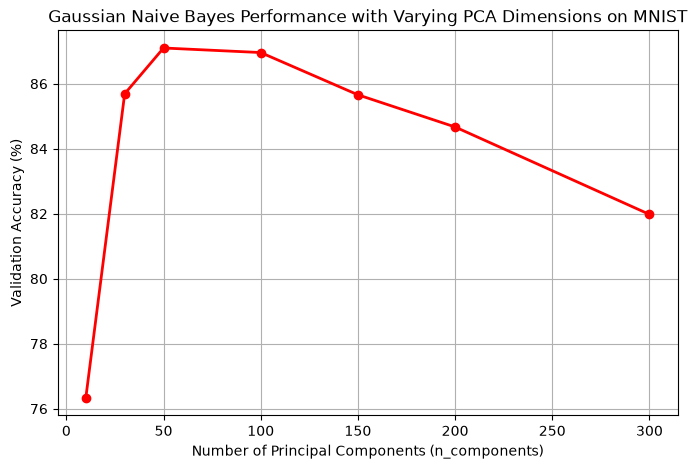

In [4]:
# Varying the number of PCA components and evaluating the performance of the Naive Bayes model
n_components_list = [10, 30, 50, 100, 150, 200, 300]
accuracies = []

for n_comp in n_components_list:
    # initial `PCA` with the specified number of components
    pca = PCA(n_components=n_comp)
    X_train_pca = pca.fit_transform(X_train_scaled)  # reduce the training data to n_comp dimensions
    X_val_pca = pca.transform(X_val_scaled)  # trans form the validation data to the same PCA space

    # training the Naive Bayes model on the PCA-reduced data
    model = NaiveBayes(log_pdf=gaussian_log_pdf)
    model.fit(X_train_pca, y_train)

    # 3. Dự đoán và tính độ chính xác
    y_pred = model.predict(X_val_pca)
    acc = accuracy_score(y_val, y_pred)
    accuracies.append(acc)
    print(f"Số chiều: {n_comp:3d} | Accuracy: {acc * 100:.2f}%")

# draw the performance plot
plt.figure(figsize=(8, 5))
plt.plot(
    n_components_list,
    [a * 100 for a in accuracies],
    marker='o',
    color='r',
    linestyle='-',
    linewidth=2,
)
plt.title(
    'Gaussian Naive Bayes Performance with Varying PCA Dimensions on MNIST'
)
plt.xlabel('Number of Principal Components (n_components)')
plt.ylabel('Validation Accuracy (%)')
plt.grid(True)
plt.show()

### 2.1.2 Naive Bayes (Multinomial_log_pdf)

In [5]:
from sklearn.metrics import classification_report
nb_model = NaiveBayes(log_pdf = multinomial_log_pdf)
# train the model
nb_model.fit(X_train_unnorm, y_train)
nb_y_pred = nb_model.predict(X_test_unnorm)
print("Đã huấn luyện mô hình Naive Bayes thành công!")

print("Classification Report:")
print(classification_report(y_test, nb_y_pred, target_names= nb_model.classes.astype(str)))
accuracy_nb = np.mean(nb_y_pred == y_test)
print(f"Độ chính xác của mô hình Naive Bayes (Multinomial_log_pdf) trên tập kiểm tra: {accuracy_nb:.2%}")
time_nb = nb_model.count_training_time
print(f"thời gian chạy Naive_Bayes: {time_nb:.4f} giây")

Đã huấn luyện mô hình Naive Bayes thành công!
Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93       980
           1       0.91      0.93      0.92      1135
           2       0.90      0.83      0.86      1032
           3       0.79      0.84      0.82      1010
           4       0.85      0.75      0.79       982
           5       0.86      0.66      0.75       892
           6       0.89      0.90      0.89       958
           7       0.94      0.83      0.88      1028
           8       0.66      0.80      0.72       974
           9       0.71      0.85      0.77      1009

    accuracy                           0.84     10000
   macro avg       0.84      0.83      0.83     10000
weighted avg       0.84      0.84      0.84     10000

Độ chính xác của mô hình Naive Bayes (Multinomial_log_pdf) trên tập kiểm tra: 83.51%
thời gian chạy Naive_Bayes: 0.2385 giây


## 2.2 Logistic Regression

In [6]:
learning_rates = [0.01, 0.03, 0.1, 0.3]
epoch_values = [10, 30, 60]

X_train = np.asarray(X_train_scaled)
X_val = np.asarray(X_val_scaled)
y_train_array = np.asarray(y_train)
y_val_array = np.asarray(y_val)

results = []
best_model = None
best_result = None
print(f"Number of configurations: {len(learning_rates) * len(epoch_values)}")

Number of configurations: 12


### 2.2.1 Train model and save static values 

In [7]:
for learning_rate in learning_rates:
    for n_epochs in epoch_values:
        model = LogisticRegression(
            learning_rate=learning_rate,
            n_epochs=n_epochs,
            batch_size=256,
            reg_strength=1e-4,
            random_state=42,
            verbose=False,
            has_aug_data=False,
        )

        started = time.perf_counter()

        try:
            model.fit(X_train, y_train_array)
            training_seconds = time.perf_counter() - started
            time_lr = training_seconds

            train_accuracy = model.score(X_train, y_train_array)
            val_accuracy = model.score(X_val, y_val_array)
            accuracy_lr = val_accuracy

        except FloatingPointError as error:
            print(
                f"Failed: lr={learning_rate}, epochs={n_epochs}. {error}",
                flush=True,
            )
            continue

        record = {
            "learning_rate": learning_rate,
            "n_epochs": n_epochs,
            "train_accuracy": train_accuracy,
            "val_accuracy": val_accuracy,
            "training_seconds": training_seconds,
            "loss_history": model.loss_history_.copy(),
        }
        results.append(record)

        if best_result is None or val_accuracy > best_result["val_accuracy"]:
            best_model = model
            best_result = record

        print(
            f"lr={learning_rate:<5g} | epochs={n_epochs:<3} | "
            f"Train={train_accuracy:.2%} | Val={val_accuracy:.2%} | "
            f"Training time={training_seconds:.1f}s",
            flush=True,
        )

lr=0.01  | epochs=10  | Train=87.68% | Val=87.57% | Training time=2.3s
lr=0.01  | epochs=30  | Train=89.71% | Val=89.58% | Training time=2.4s
lr=0.01  | epochs=60  | Train=90.67% | Val=90.47% | Training time=4.6s
lr=0.03  | epochs=10  | Train=89.74% | Val=89.55% | Training time=1.6s
lr=0.03  | epochs=30  | Train=91.14% | Val=90.76% | Training time=2.4s
lr=0.03  | epochs=60  | Train=91.85% | Val=91.39% | Training time=4.5s
lr=0.1   | epochs=10  | Train=91.27% | Val=90.86% | Training time=0.8s
lr=0.1   | epochs=30  | Train=92.19% | Val=91.61% | Training time=3.0s
lr=0.1   | epochs=60  | Train=92.67% | Val=92.00% | Training time=4.6s
lr=0.3   | epochs=10  | Train=92.25% | Val=91.72% | Training time=0.8s
lr=0.3   | epochs=30  | Train=92.72% | Val=91.90% | Training time=3.2s
lr=0.3   | epochs=60  | Train=93.13% | Val=92.04% | Training time=4.8s


### 2.2.2 Bảng xếp hạng các mô hình

In [8]:
if not results:
    raise RuntimeError("No configuration trained successfully.")

ranked_results = sorted(
    results,
    key=lambda item: item["val_accuracy"],
    reverse=True,
)

print(
    f"{'Rank':<6}{'LR':>9}{'Epochs':>9}"
    f"{'Train acc':>13}{'Val acc':>13}{'Gap (pp)':>11}{'Time (s)':>12}"
)

for rank, item in enumerate(ranked_results, start=1):
    gap = 100 * (item["train_accuracy"] - item["val_accuracy"])

    print(
        f"{rank:<6}"
        f"{item['learning_rate']:>9g}"
        f"{item['n_epochs']:>9}"
        f"{item['train_accuracy']:>13.2%}"
        f"{item['val_accuracy']:>13.2%}"
        f"{gap:>11.2f}"
        f"{item['training_seconds']:>12.1f}"
    )

print(
    f"\nBest configuration: lr={best_result['learning_rate']}, "
    f"epochs={best_result['n_epochs']}"
)
print(f"Best validation accuracy: {best_result['val_accuracy']:.2%}")

Rank         LR   Epochs    Train acc      Val acc   Gap (pp)    Time (s)
1           0.3       60       93.13%       92.04%       1.09         4.8
2           0.1       60       92.67%       92.00%       0.67         4.6
3           0.3       30       92.72%       91.90%       0.82         3.2
4           0.3       10       92.25%       91.72%       0.53         0.8
5           0.1       30       92.19%       91.61%       0.58         3.0
6          0.03       60       91.85%       91.39%       0.46         4.5
7           0.1       10       91.27%       90.86%       0.41         0.8
8          0.03       30       91.14%       90.76%       0.38         2.4
9          0.01       60       90.67%       90.47%       0.20         4.6
10         0.01       30       89.71%       89.58%       0.13         2.4
11         0.03       10       89.74%       89.55%       0.19         1.6
12         0.01       10       87.68%       87.57%       0.11         2.3

Best configuration: lr=0.3, epochs=60

### 2.2.3 Visualize

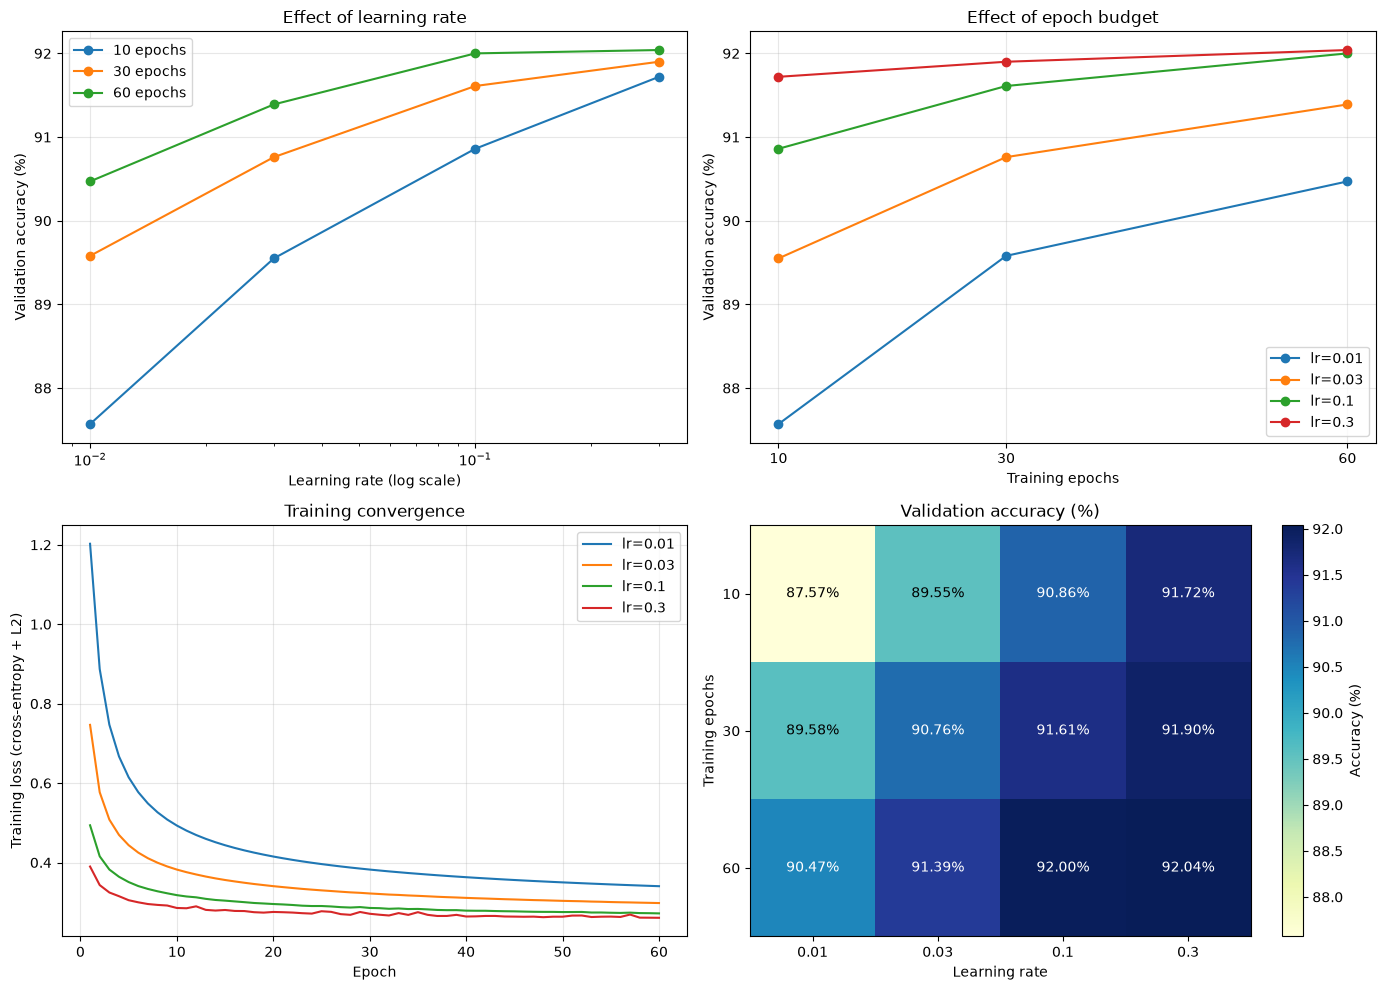

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Validation accuracy versus learning rate.
for n_epochs in epoch_values:
    selected = sorted(
        [item for item in results if item["n_epochs"] == n_epochs],
        key=lambda item: item["learning_rate"],
    )
    if not selected:
        continue

    axes[0, 0].plot(
        [item["learning_rate"] for item in selected],
        [100 * item["val_accuracy"] for item in selected],
        marker="o",
        label=f"{n_epochs} epochs",
    )

axes[0, 0].set_xscale("log")
axes[0, 0].set_xlabel("Learning rate (log scale)")
axes[0, 0].set_ylabel("Validation accuracy (%)")
axes[0, 0].set_title("Effect of learning rate")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)


# 2. Validation accuracy versus epoch budget.
for learning_rate in learning_rates:
    selected = sorted(
        [
            item for item in results
            if item["learning_rate"] == learning_rate
        ],
        key=lambda item: item["n_epochs"],
    )
    if not selected:
        continue

    axes[0, 1].plot(
        [item["n_epochs"] for item in selected],
        [100 * item["val_accuracy"] for item in selected],
        marker="o",
        label=f"lr={learning_rate:g}",
    )

axes[0, 1].set_xlabel("Training epochs")
axes[0, 1].set_ylabel("Validation accuracy (%)")
axes[0, 1].set_title("Effect of epoch budget")
axes[0, 1].set_xticks(epoch_values)
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)


# 3. Full epoch-by-epoch training loss from each LR's longest run.
for learning_rate in learning_rates:
    candidates = [
        item for item in results
        if item["learning_rate"] == learning_rate
    ]
    if not candidates:
        continue

    longest_run = max(candidates, key=lambda item: item["n_epochs"])
    losses = longest_run["loss_history"]

    axes[1, 0].plot(
        np.arange(1, len(losses) + 1),
        losses,
        label=f"lr={learning_rate:g}",
    )

axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Training loss (cross-entropy + L2)")
axes[1, 0].set_title("Training convergence")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)


# 4. Validation accuracy for every parameter combination.
accuracy_grid = np.full(
    (len(epoch_values), len(learning_rates)),
    np.nan,
)

for item in results:
    row = epoch_values.index(item["n_epochs"])
    column = learning_rates.index(item["learning_rate"])
    accuracy_grid[row, column] = 100 * item["val_accuracy"]

heatmap = axes[1, 1].imshow(
    np.ma.masked_invalid(accuracy_grid),
    cmap="YlGnBu",
    aspect="auto",
)

axes[1, 1].set_xticks(
    np.arange(len(learning_rates)),
    labels=[f"{value:g}" for value in learning_rates],
)
axes[1, 1].set_yticks(
    np.arange(len(epoch_values)),
    labels=epoch_values,
)
axes[1, 1].set_xlabel("Learning rate")
axes[1, 1].set_ylabel("Training epochs")
axes[1, 1].set_title("Validation accuracy (%)")

midpoint = (
    np.nanmin(accuracy_grid) + np.nanmax(accuracy_grid)
) / 2

for row in range(len(epoch_values)):
    for column in range(len(learning_rates)):
        value = accuracy_grid[row, column]
        if np.isfinite(value):
            axes[1, 1].text(
                column,
                row,
                f"{value:.2f}%",
                ha="center",
                va="center",
                color="white" if value > midpoint else "black",
            )

fig.colorbar(heatmap, ax=axes[1, 1], label="Accuracy (%)")
fig.tight_layout()
plt.show()

### 2.2.4 Confusion Matrix

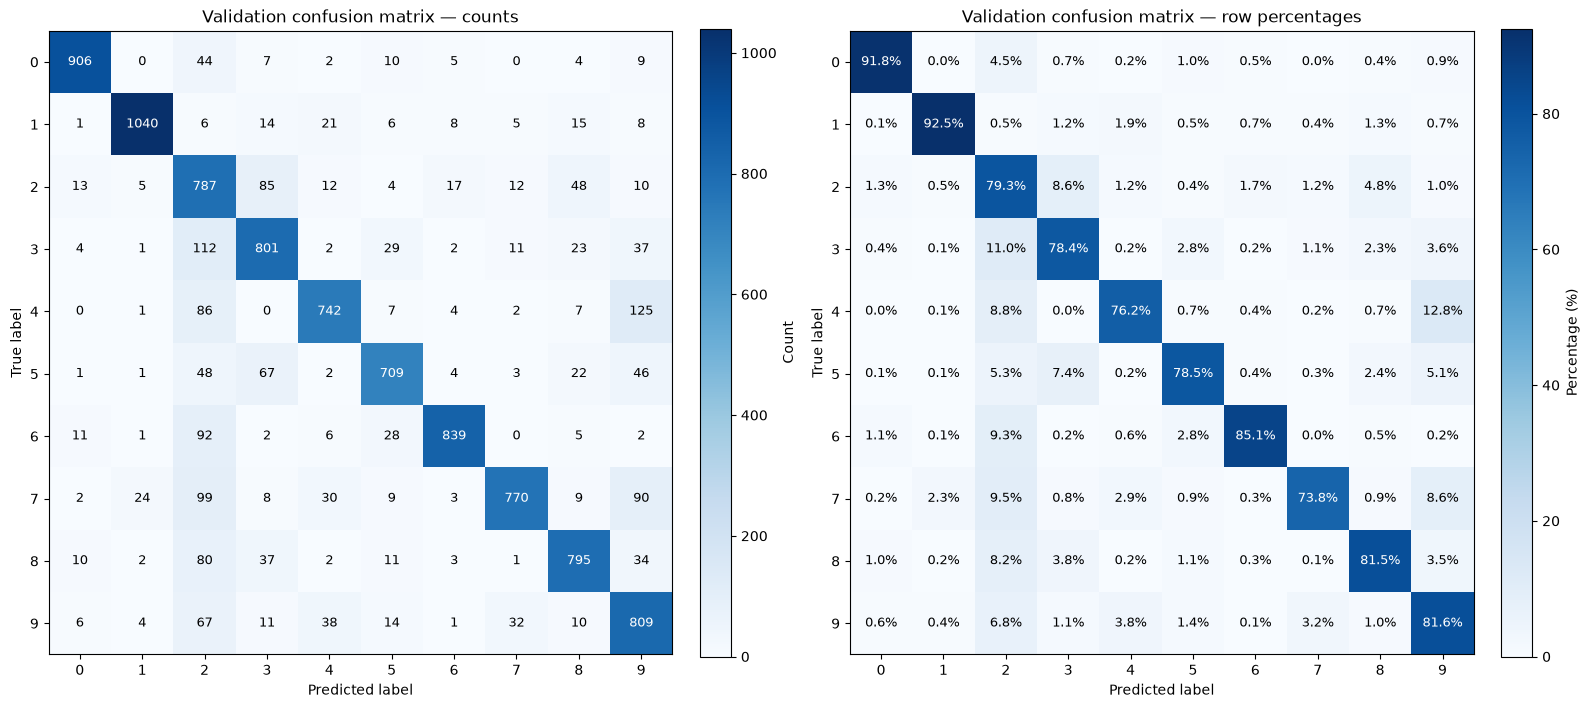

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# True labels and predicted labels
y_true = np.asarray(y_val)
y_pred = np.asarray(y_pred)
y_pred_lr = y_pred
# Class labels
class_labels = np.arange(10)
n_classes = len(class_labels)


# Confusion matrix (counts)
confusion = confusion_matrix(
    y_true,
    y_pred,
    labels=class_labels,
)

# Row-normalized confusion matrix (%)
row_sums = confusion.sum(axis=1, keepdims=True)

confusion_percent = np.divide(
    confusion,
    row_sums,
    out=np.zeros_like(confusion, dtype=float),
    where=row_sums != 0,
) * 100
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

plots = [
    (confusion, "Validation confusion matrix — counts", "Count"),
    (
        confusion_percent,
        "Validation confusion matrix — row percentages",
        "Percentage (%)",
    ),
]

for ax, (matrix, title, colorbar_label) in zip(axes, plots):
    image = ax.imshow(matrix, cmap="Blues", vmin=0)
    threshold = matrix.max() / 2

    for row in range(n_classes):
        for column in range(n_classes):
            value = matrix[row, column]
            text = (
                f"{int(value)}"
                if colorbar_label == "Count"
                else f"{value:.1f}%"
            )

            ax.text(
                column,
                row,
                text,
                ha="center",
                va="center",
                fontsize=9,
                color="white" if value > threshold else "black",
            )

    ax.set_xticks(np.arange(n_classes), labels=class_labels)
    ax.set_yticks(np.arange(n_classes), labels=class_labels)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(title)

    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04,
                 label=colorbar_label)

fig.tight_layout()
plt.show()

## 2.3 SVM

In [11]:
X_train = np.asarray(X_train_scaled)
X_val = np.asarray(X_val_scaled)
y_train_array = np.asarray(y_train)
y_val_array = np.asarray(y_val)

learning_rates = [0.001, 0.003, 0.01, 0.03]
epoch_values = [10, 30, 60]

results = []
best_svm = None
best_result = None

print(
    f"Training samples: {len(X_train)} | "
    f"Validation samples: {len(X_val)}"
)
print(f"Number of configurations: {len(learning_rates) * len(epoch_values)}")

Training samples: 50000 | Validation samples: 10000
Number of configurations: 12


### 2.3.1 Train model and save static values

In [12]:
for learning_rate in learning_rates:
    for n_epochs in epoch_values:
        model = MulticlassLinearSVM(
            learning_rate=learning_rate,
            n_epochs=n_epochs,
            batch_size=256,
            reg_strength=1e-4,
            learning_rate_decay=0.05,
            random_state=42,
            verbose=False,
            has_aug_data=False,
        )

        started = time.perf_counter()

        try:
            model.fit(X_train, y_train_array)
            training_seconds = time.perf_counter() - started

            train_accuracy = model.score(X_train, y_train_array)
            val_accuracy = model.score(X_val, y_val_array)

        except FloatingPointError as error:
            print(
                f"Failed: lr={learning_rate}, epochs={n_epochs}. "
                f"{error}",
                flush=True,
            )
            continue

        record = {
            "learning_rate": learning_rate,
            "n_epochs": n_epochs,
            "train_accuracy": train_accuracy,
            "val_accuracy": val_accuracy,
            "training_seconds": training_seconds,
            "loss_history": model.loss_history_.copy(),
        }
        results.append(record)

        if (
            best_result is None
            or val_accuracy > best_result["val_accuracy"]
        ):
            best_svm = model
            best_result = record

        print(
            f"lr={learning_rate:<6g} | "
            f"epochs={n_epochs:<3} | "
            f"Train={train_accuracy:.2%} | "
            f"Val={val_accuracy:.2%} | "
            f"Time={training_seconds:.1f}s",
            flush=True,
        )

if best_svm is None:
    raise RuntimeError("No configuration trained successfully.")

lr=0.001  | epochs=10  | Train=88.00% | Val=88.03% | Time=1.2s
lr=0.001  | epochs=30  | Train=89.22% | Val=89.32% | Time=1.5s
lr=0.001  | epochs=60  | Train=89.75% | Val=89.80% | Time=4.0s
lr=0.003  | epochs=10  | Train=89.63% | Val=89.74% | Time=0.6s
lr=0.003  | epochs=30  | Train=90.55% | Val=90.42% | Time=1.4s
lr=0.003  | epochs=60  | Train=90.93% | Val=90.89% | Time=3.7s
lr=0.01   | epochs=10  | Train=90.92% | Val=90.78% | Time=0.5s
lr=0.01   | epochs=30  | Train=91.60% | Val=91.45% | Time=1.5s
lr=0.01   | epochs=60  | Train=91.85% | Val=91.62% | Time=3.6s
lr=0.03   | epochs=10  | Train=91.72% | Val=91.57% | Time=0.5s
lr=0.03   | epochs=30  | Train=92.30% | Val=92.02% | Time=2.1s
lr=0.03   | epochs=60  | Train=92.47% | Val=92.11% | Time=2.9s


### 2.3.2 Rank Table

In [13]:
ranked_results = sorted(
    results,
    key=lambda item: item["val_accuracy"],
    reverse=True,
)

print(
    f"{'Rank':<6}{'LR':>9}{'Epochs':>9}"
    f"{'Train acc':>13}{'Val acc':>13}"
    f"{'Gap (pp)':>11}{'Time (s)':>12}"
)

for rank, item in enumerate(ranked_results, start=1):
    gap = 100 * (
        item["train_accuracy"] - item["val_accuracy"]
    )

    print(
        f"{rank:<6}"
        f"{item['learning_rate']:>9g}"
        f"{item['n_epochs']:>9}"
        f"{item['train_accuracy']:>13.2%}"
        f"{item['val_accuracy']:>13.2%}"
        f"{gap:>11.2f}"
        f"{item['training_seconds']:>12.1f}"
    )

print(
    f"\nBest configuration: "
    f"lr={best_result['learning_rate']}, "
    f"epochs={best_result['n_epochs']}"
)
print(
    f"Best validation accuracy: "
    f"{best_result['val_accuracy']:.4%}"
)

Rank         LR   Epochs    Train acc      Val acc   Gap (pp)    Time (s)
1          0.03       60       92.47%       92.11%       0.36         2.9
2          0.03       30       92.30%       92.02%       0.28         2.1
3          0.01       60       91.85%       91.62%       0.23         3.6
4          0.03       10       91.72%       91.57%       0.15         0.5
5          0.01       30       91.60%       91.45%       0.15         1.5
6         0.003       60       90.93%       90.89%       0.04         3.7
7          0.01       10       90.92%       90.78%       0.14         0.5
8         0.003       30       90.55%       90.42%       0.13         1.4
9         0.001       60       89.75%       89.80%      -0.05         4.0
10        0.003       10       89.63%       89.74%      -0.11         0.6
11        0.001       30       89.22%       89.32%      -0.10         1.5
12        0.001       10       88.00%       88.03%      -0.03         1.2

Best configuration: lr=0.03, epochs=6

### 2.3.3 Static

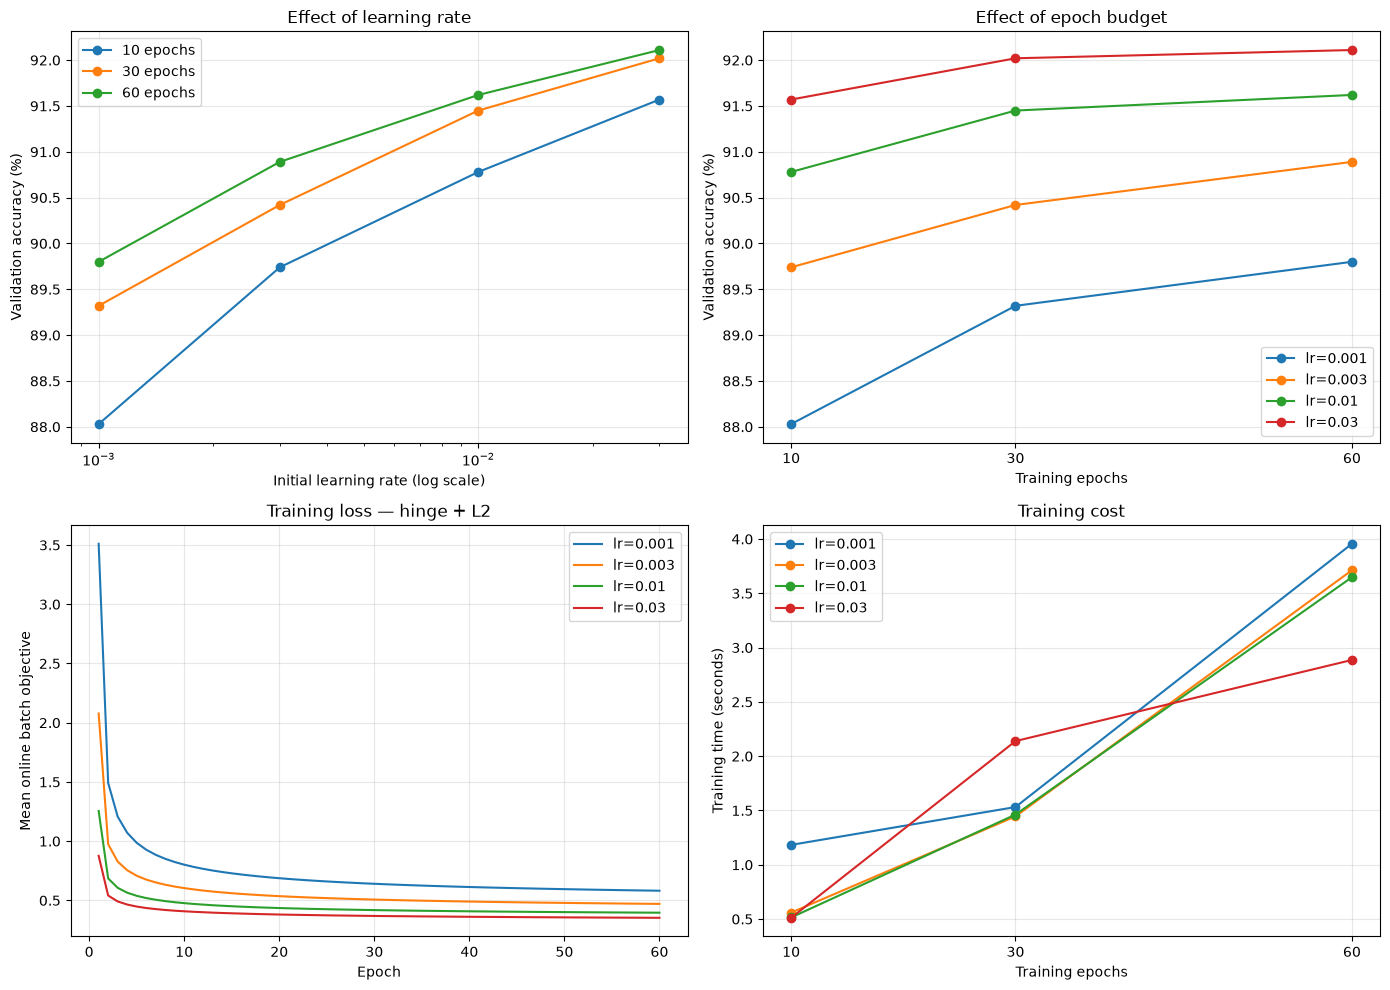

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Validation accuracy versus initial learning rate.
for n_epochs in epoch_values:
    selected = sorted(
        [r for r in results if r["n_epochs"] == n_epochs],
        key=lambda r: r["learning_rate"],
    )
    if not selected:
        continue

    axes[0, 0].plot(
        [r["learning_rate"] for r in selected],
        [100 * r["val_accuracy"] for r in selected],
        marker="o",
        label=f"{n_epochs} epochs",
    )

axes[0, 0].set_xscale("log")
axes[0, 0].set_xlabel("Initial learning rate (log scale)")
axes[0, 0].set_ylabel("Validation accuracy (%)")
axes[0, 0].set_title("Effect of learning rate")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Validation accuracy versus epoch budget.
for learning_rate in learning_rates:
    selected = sorted(
        [r for r in results if r["learning_rate"] == learning_rate],
        key=lambda r: r["n_epochs"],
    )
    if not selected:
        continue

    axes[0, 1].plot(
        [r["n_epochs"] for r in selected],
        [100 * r["val_accuracy"] for r in selected],
        marker="o",
        label=f"lr={learning_rate:g}",
    )

axes[0, 1].set_xlabel("Training epochs")
axes[0, 1].set_ylabel("Validation accuracy (%)")
axes[0, 1].set_title("Effect of epoch budget")
axes[0, 1].set_xticks(epoch_values)
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# 3. Loss history from the longest successful run for each LR.
for learning_rate in learning_rates:
    candidates = [
        r for r in results
        if r["learning_rate"] == learning_rate
    ]
    if not candidates:
        continue

    longest_run = max(candidates, key=lambda r: r["n_epochs"])
    losses = longest_run["loss_history"]

    axes[1, 0].plot(
        np.arange(1, len(losses) + 1),
        losses,
        label=f"lr={learning_rate:g}",
    )

axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Mean online batch objective")
axes[1, 0].set_title("Training loss — hinge + L2")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# 4. Training time versus epoch budget.
for learning_rate in learning_rates:
    selected = sorted(
        [r for r in results if r["learning_rate"] == learning_rate],
        key=lambda r: r["n_epochs"],
    )
    if not selected:
        continue

    axes[1, 1].plot(
        [r["n_epochs"] for r in selected],
        [r["training_seconds"] for r in selected],
        marker="o",
        label=f"lr={learning_rate:g}",
    )

axes[1, 1].set_xlabel("Training epochs")
axes[1, 1].set_ylabel("Training time (seconds)")
axes[1, 1].set_title("Training cost")
axes[1, 1].set_xticks(epoch_values)
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

### 2.3.4 Confusion Matrix

Validation accuracy: 92.1100%
Correct predictions: 9211 / 10000
Incorrect predictions: 789


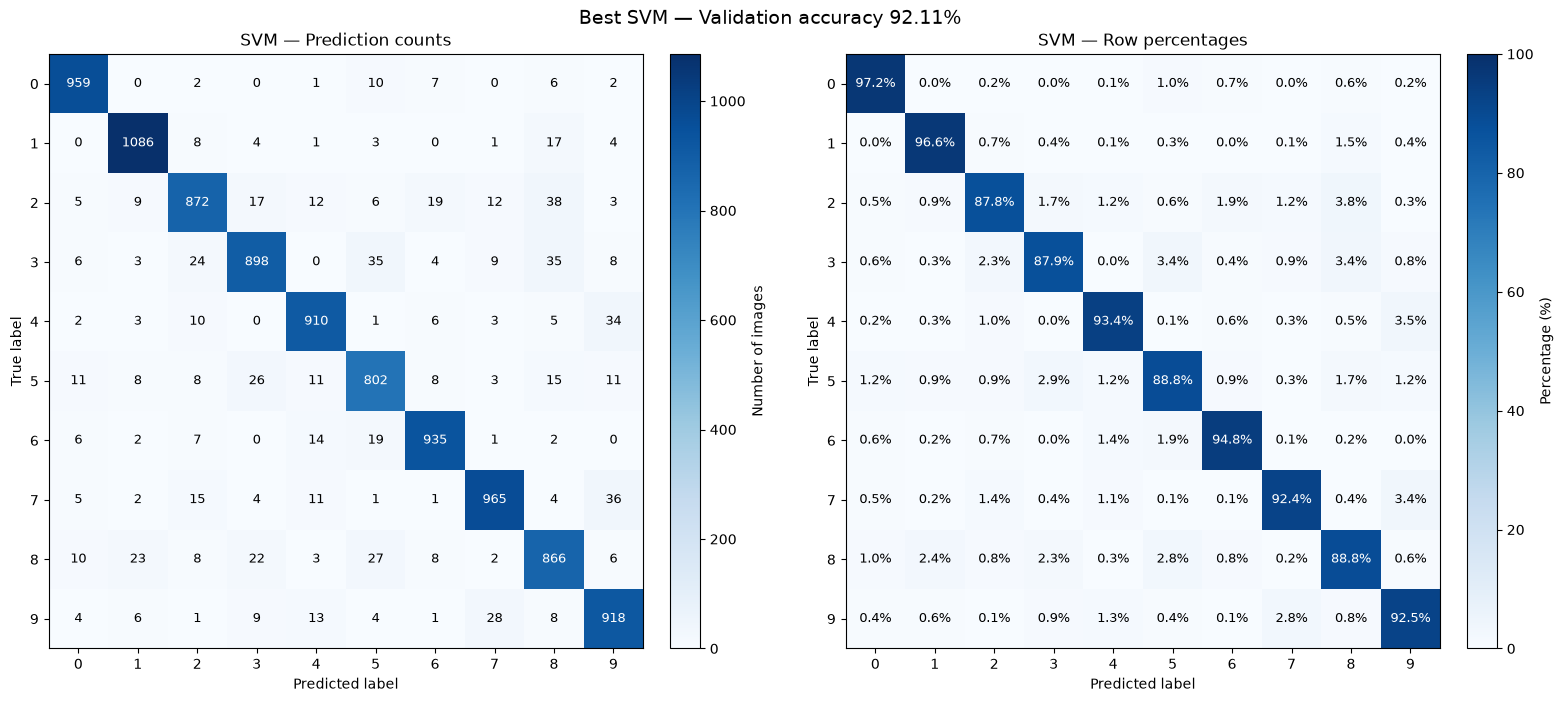

In [15]:
y_true = np.asarray(y_val_array)
y_pred = best_svm.predict(X_val)

# Include all trained classes and any labels appearing in validation.
class_labels = np.union1d(
    best_svm.classes_,
    np.union1d(y_true, y_pred),
)
n_classes = len(class_labels)

true_indices = np.searchsorted(class_labels, y_true)
pred_indices = np.searchsorted(class_labels, y_pred)

cm = np.zeros((n_classes, n_classes), dtype=np.int64)
np.add.at(cm, (true_indices, pred_indices), 1)

row_totals = cm.sum(axis=1, keepdims=True)
cm_percent = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=np.float64),
    where=row_totals != 0,
) * 100

accuracy = np.mean(y_true == y_pred)

print(f"Validation accuracy: {accuracy:.4%}")
print(f"Correct predictions: {np.trace(cm)} / {cm.sum()}")
print(f"Incorrect predictions: {cm.sum() - np.trace(cm)}")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, matrix, normalized in zip(
    axes, [cm, cm_percent], [False, True]
):
    vmax = 100 if normalized else max(1, int(cm.max()))
    image = ax.imshow(
        matrix, cmap="Blues", vmin=0, vmax=vmax
    )

    for row in range(n_classes):
        for column in range(n_classes):
            value = matrix[row, column]
            label = (
                f"{value:.1f}%"
                if normalized else str(int(value))
            )

            ax.text(
                column,
                row,
                label,
                ha="center",
                va="center",
                fontsize=9,
                color="white" if value > vmax / 2 else "black",
            )

    ax.set_xticks(np.arange(n_classes), labels=class_labels)
    ax.set_yticks(np.arange(n_classes), labels=class_labels)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(
        "SVM — Row percentages"
        if normalized else "SVM — Prediction counts"
    )

    fig.colorbar(
        image,
        ax=ax,
        fraction=0.046,
        pad=0.04,
        label="Percentage (%)" if normalized else "Number of images",
    )

fig.suptitle(
    f"Best SVM — Validation accuracy {accuracy:.2%}",
    fontsize=14,
)
fig.tight_layout()
plt.show()

## 2.4 MLP

In [16]:
import torch
import torch.nn as nn
from src.algorithm.MLP import MLP

mlp_model = MLP()

mlp_model.fit(X_train_scaled, y_train, X_val_scaled, y_val)

mlp_y_pred = mlp_model.predict(X_test_scaled)

y_test = np.asarray(y_test)
accuracy = np.mean(mlp_y_pred == y_test)


print("Test accuracy:", accuracy)

Test accuracy: 0.9723


In [17]:
print(type(mlp_model.history_))
print(mlp_model.history_)

<class 'dict'>
{'train_loss': [0.35800231446266173, 0.23507488252639772, 0.21023139815330505, 0.1614122651052475, 0.13865048331737517, 0.12814817790985109, 0.10950089032173156, 0.10900826797962189, 0.09506610990762711, 0.08775900232315063, 0.08345612097263336, 0.07050602313041687, 0.0765573057460785, 0.0656260064291954, 0.05189816697359085, 0.05392098040342331, 0.04652064449310303, 0.04176239738702774, 0.037764400424957274, 0.04699621449589729], 'train_acc': [0.89148, 0.93258, 0.93698, 0.95398, 0.96062, 0.96268, 0.96852, 0.96686, 0.9722, 0.97486, 0.9748, 0.97992, 0.97756, 0.9813, 0.98664, 0.98532, 0.98812, 0.98948, 0.99106, 0.98686], 'val_loss': [0.36607393970489505, 0.2506703183233738, 0.22553932240009308, 0.18491713139414787, 0.16626331587731838, 0.1598071059912443, 0.1411165510505438, 0.14159247544556855, 0.1341079064667225, 0.1282875294059515, 0.12329104089736939, 0.11322800786495209, 0.12662264488302172, 0.10972352213710547, 0.10052520414926111, 0.10553823349997402, 0.098471168874

### 2.4.1 Hyperparameter tuning

**Default baseline**

learning_rate = 0.1,

n_epochs = 20,

batch_size = 256,

momentum = 0.0,

weight_decay = 0.0,

hidden_sizes = (256, 128),

activation = "relu",

p_drop = 0.0,

init = "he".

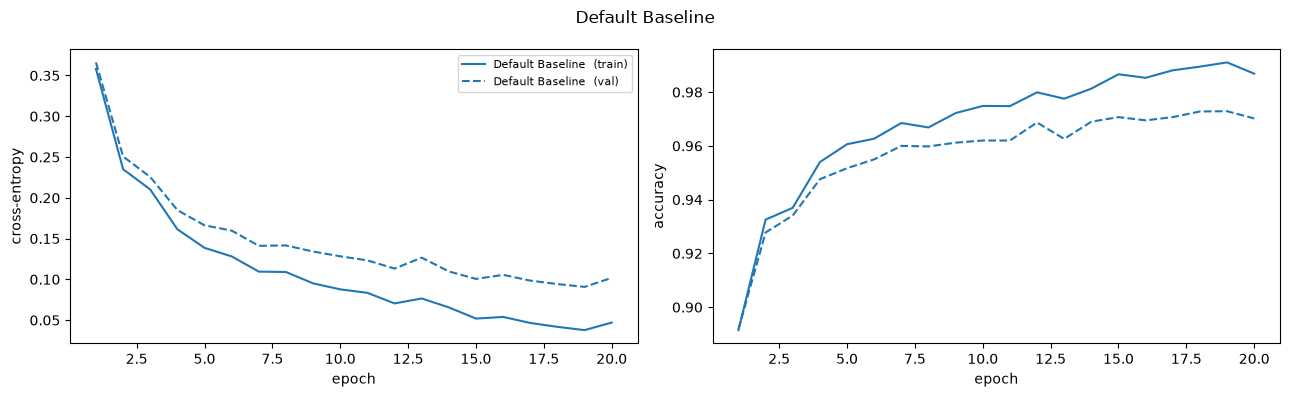

In [18]:
MLP.acc_loss_history_plot({"Default Baseline ": mlp_model.history_}, "Default Baseline")

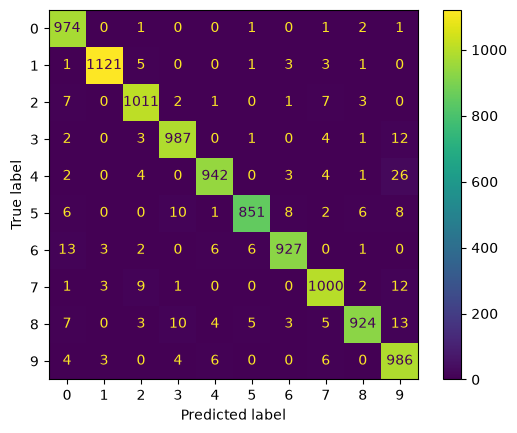

In [19]:
mlp_cm = confusion_matrix(y_test, mlp_y_pred)

ConfusionMatrixDisplay(confusion_matrix=mlp_cm).plot()
plt.show()

### 2.4.2 Hyperparameter Tuning

**Learning rate**

### Cách khảo sát Learning Rate

Thử các giá trị `0.01`, `0.05`, `0.1`, `0.5`, `1`; mỗi giá trị huấn luyện một MLP mới trên cùng tập train và validation. Các siêu tham số khác giữ mặc định. So sánh Train/Validation Loss và Accuracy theo Epoch để đánh giá tốc độ hội tụ, hiệu suất và độ ổn định. Đây là khảo sát từng tham số, chưa xét tương tác với tham số khác.

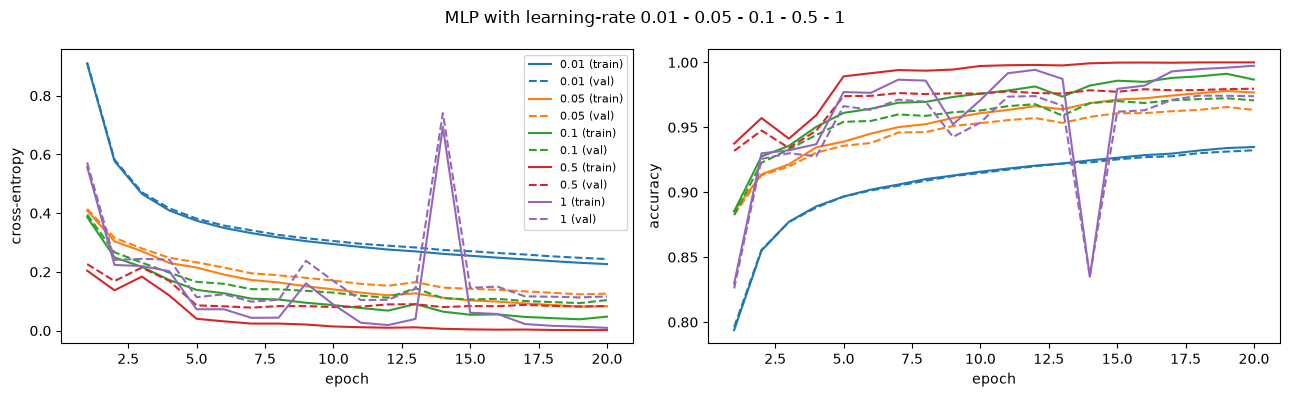

In [20]:
LRS = [0.01, 0.05, 0.1, 0.5, 1]
mlp_lr_result = {}

for lr_test in LRS:
    mlp_lr_model = MLP(learning_rate=lr_test, verbose=False)
    mlp_lr_model.fit(X_train_scaled, y_train, X_val_scaled, y_val)
    mlp_lr_result[lr_test] = (mlp_lr_model.history_)
    
MLP.acc_loss_history_plot(mlp_lr_result, "MLP with learning-rate 0.01 - 0.05 - 0.1 - 0.5 - 1")

### Nhận xét – Learning Rate

Từ Learning Curves, Learning Rate `0.01` học chậm và có Validation Accuracy thấp nhất trong các cấu hình. Các mức `0.05` và `0.1` cải thiện rõ rệt. Mức `0.5` đạt Accuracy cao và Loss thấp, đồng thời khá ổn định trong lần chạy này. Mức `1` có dao động mạnh, thể hiện rõ ở Loss và Accuracy quanh Epoch 14. Vì vậy, `0.5` là ứng viên tốt trong phạm vi đã thử; cần chạy lại với nhiều seed để xác nhận độ ổn định.

**Momentum**

### Cách khảo sát Momentum

Thử `momentum` bằng `0.1`, `0.5`, `0.9`, `0.95`; mỗi giá trị dùng một MLP mới và cùng dữ liệu train/validation. Các tham số khác giữ mặc định. So sánh Learning Curves để xem Momentum ảnh hưởng thế nào đến tốc độ giảm Loss, độ dao động và Validation Accuracy.

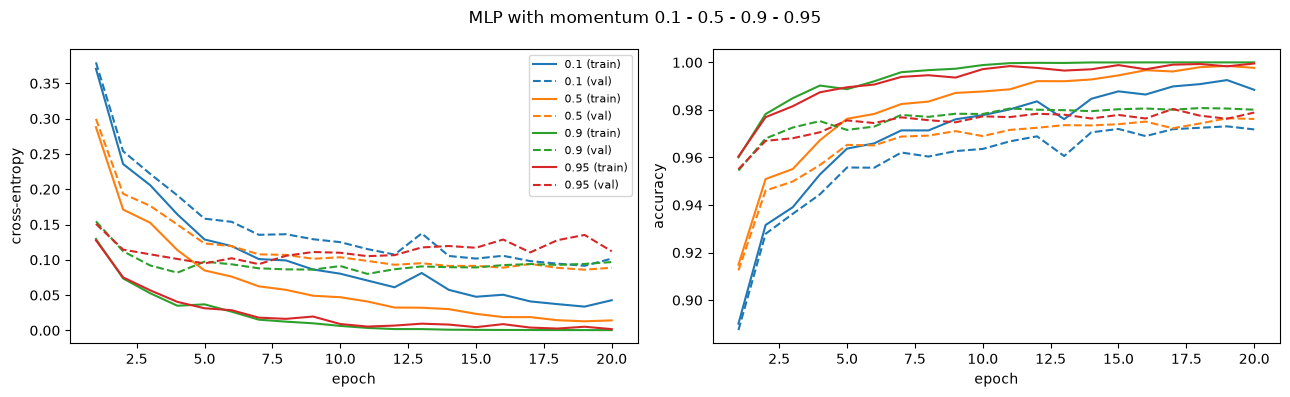

In [21]:
MOMENT = [0.1, 0.5, 0.9, 0.95]
mlp_momen_result = {}

for mm in MOMENT:
    mlp_momen_model = MLP(momentum= mm, verbose=False)
    mlp_momen_model.fit(X_train_scaled, y_train, X_val_scaled, y_val)
    mlp_momen_result[mm] = (mlp_momen_model.history_)
    
MLP.acc_loss_history_plot(mlp_momen_result, "MLP with momentum 0.1 - 0.5 - 0.9 - 0.95")

### Nhận xét – Momentum

Các đường học cho thấy Momentum `0.5`, `0.9` và `0.95` đều cải thiện nhanh hơn `0.1`. Mức `0.9` có Train Loss giảm rất thấp và Validation Accuracy duy trì ở mức cao; `0.95` cũng cho kết quả tốt nhưng Validation Loss dao động hơn ở một số Epoch. Trong phạm vi thử nghiệm này, `0.9` là lựa chọn đáng cân nhắc. Cần kiểm tra thêm với nhiều lần chạy để xác nhận.

### Khảo sát tương tác Learning Rate và Momentum

Huấn luyện mô hình cho từng cặp giá trị trong `LRS` và `MOMENT`. Lưu Validation Accuracy tốt nhất của mỗi mô hình vào ma trận rồi biểu diễn bằng Heatmap. Màu sắc giúp nhận biết vùng kết hợp hai siêu tham số cho kết quả tốt. Các tham số khác giữ mặc định.

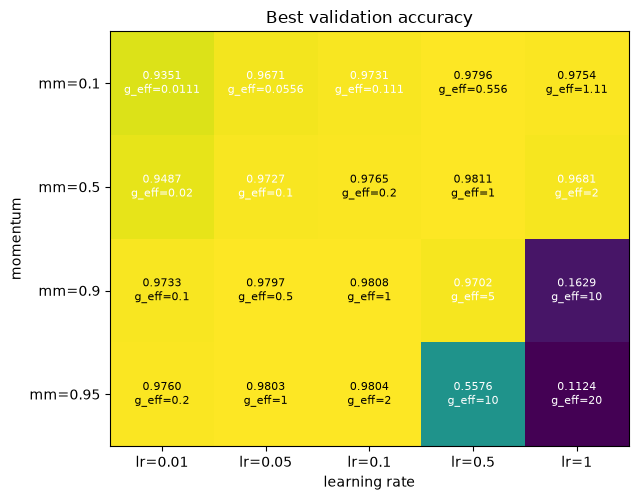

In [22]:
lr_mm_relation = np.full((len(MOMENT), len(LRS)), np.nan)
for i, mm in enumerate(MOMENT):
    for j, lr in enumerate(LRS):
        mlp_lr_mm_model = MLP(learning_rate=lr, momentum=mm, verbose=False)
        mlp_lr_mm_model.fit(X_train_scaled, y_train, X_val_scaled, y_val)

        lr_mm_relation[i, j] = max(mlp_lr_mm_model.history_["val_acc"])

MLP.plot_heatmap(lr_mm_relation, [f"mm={a}" for a in MOMENT], [f"lr={l}" for l in LRS], "momentum", "learning rate",
    "Best validation accuracy",
    cell_note=lambda i, j: f"g_eff={LRS[j] / (1 - MOMENT[i]):.3g}")

### Nhận xét – Tương tác Learning Rate và Momentum

Heatmap cho phép so sánh đồng thời hai tham số thay vì đánh giá riêng lẻ. Mỗi ô biểu diễn Validation Accuracy tốt nhất trong quá trình huấn luyện của một cặp cấu hình. Nếu learning rate và momentum đồng thời quá lớn làm giảm mạnh độ chính xác của mô hình. Dựa trên khảo sát độc lập `learning rate`, `momentum` ở trên và kết quả của khảo sát này thì lựa chọn phù hợp là `learning rate = 0,1` và `momentum = 0.9`

**Batch size**

### So sánh chi phí huấn luyện giữa các Batch Size

Với từng Batch Size, huấn luyện lại mô hình và ghi số lần cập nhật, thời gian trung bình mỗi Epoch cùng Validation Accuracy tốt nhất. Bảng này bổ sung góc nhìn chi phí tính toán, giúp cân nhắc sự đánh đổi giữa hiệu suất và thời gian huấn luyện.

In [23]:
BATCH_SIZES = [16,  64, 128, 256, 1024]
bs_rows = []   # moi phan tu: (batch_size, number of updates, giay/epoch, best val acc)

for bs in BATCH_SIZES:
    mlp_batchsize_model = MLP(batch_size= bs, verbose=False)
    mlp_batchsize_model.fit(X_train_scaled, y_train, X_val_scaled, y_val)

    updates = int(np.ceil(len(X_train_scaled) / bs)) * mlp_batchsize_model.n_epochs
    seconds_per_epoch = float(np.mean(mlp_batchsize_model.history_["time"])) if mlp_batchsize_model.history_["time"] else float("nan")
    val_acc = float(max(mlp_batchsize_model.history_["val_acc"])) if mlp_batchsize_model.history_["val_acc"] else float("nan")
    bs_rows.append((bs, updates, seconds_per_epoch, val_acc))

print(f"{'batch':>6} | {'number of updates':>11} | {'s/epoch':>7} | {'best val acc':>12}")
for bs, nu, t, va in bs_rows:
    print(f"{bs:>6} | {nu:>11} | {t:7.2f} | {va:12.4f}")

 batch | number of updates | s/epoch | best val acc
    16 |       62500 |   23.23 |       0.9827
    64 |       15640 |    0.39 |       0.9792
   128 |        7820 |    0.24 |       0.9770
   256 |        3920 |    0.18 |       0.9724
  1024 |         980 |    0.10 |       0.9538


### Nhận xét – Chi phí huấn luyện theo Batch Size

Bảng kết quả cho thấy Batch Size `16` có Validation Accuracy tốt nhất (0.9823), nhưng cần 62.500 lần cập nhật và khoảng 1,31 giây mỗi Epoch. Khi Batch Size tăng lên `1024`, thời gian mỗi Epoch giảm còn 0,12 giây nhưng Accuracy giảm còn 0.9538. Batch Size `64` là lựa chọn cân bằng tương đối: 0,40 giây/Epoch và Accuracy 0.9792. Các giá trị này là kết quả của lần chạy hiện tại.

**Weight decay**

**Cách khảo sát Weight Decay**

Thử `0.0001`, `0.001`, `0.01`, `0.06` với các tham số khác mặc định; sau đó khảo sát hai giá trị nhỏ hơn khi cố định `momentum=0.9`. So sánh Learning Curves, đặc biệt khoảng cách Train/Validation, để đánh giá tác dụng regularization. Hai giai đoạn có cấu hình Momentum khác nhau nên không so sánh trực tiếp.

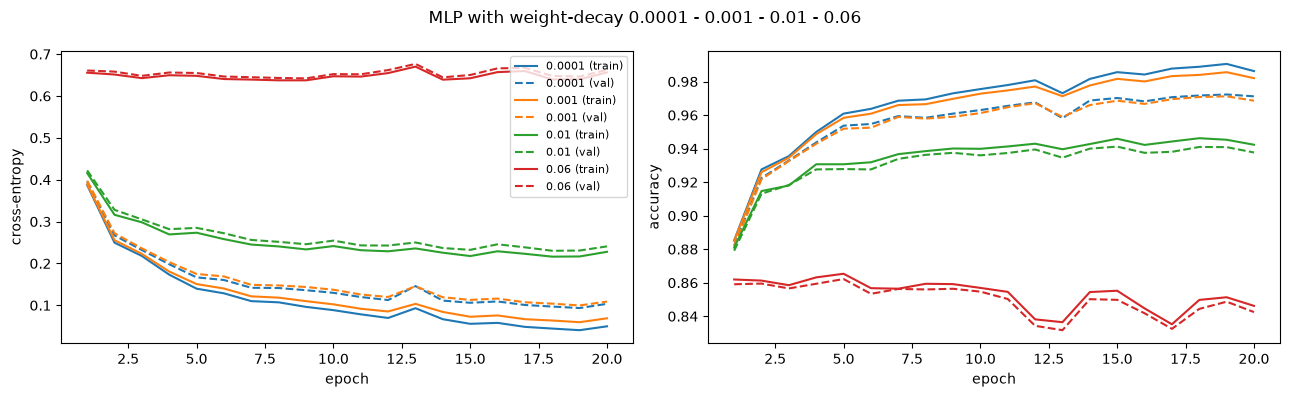

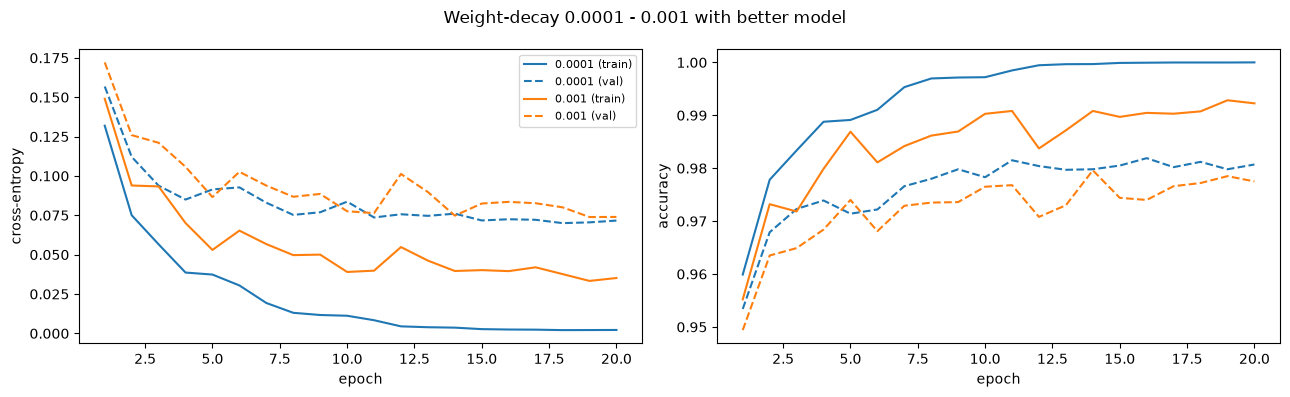

In [24]:
WEI_DECAY = [0.0001, 0.001, 0.01, 0.06]
mlp_wdecay_result = {}

for wd in WEI_DECAY:
    mlp_wdecay_model = MLP(weight_decay= wd, verbose=False)
    mlp_wdecay_model.fit(X_train_scaled, y_train, X_val_scaled, y_val)
    mlp_wdecay_result[wd] = (mlp_wdecay_model.history_)
    
MLP.acc_loss_history_plot(mlp_wdecay_result, "MLP with weight-decay 0.0001 - 0.001 - 0.01 - 0.06")


WEI_DECAY = [0.0001, 0.001]
mlp_wdecay_result = {}

for wd in WEI_DECAY:
    mlp_wdecay_model = MLP(weight_decay= wd, momentum= 0.9, verbose=False)
    mlp_wdecay_model.fit(X_train_scaled, y_train, X_val_scaled, y_val)
    mlp_wdecay_result[wd] = (mlp_wdecay_model.history_)
    
MLP.acc_loss_history_plot(mlp_wdecay_result, "Weight-decay 0.0001 - 0.001 with better model")

**Nhận xét – Weight Decay**

Ở lượt khảo sát đầu, Weight Decay `0.0001` và `0.001` cho Validation Accuracy cao hơn `0.01`; mức `0.06` khiến Loss cao và Accuracy thấp, cho thấy regularization quá mạnh trong cấu hình này. Ở lượt khảo sát thứ hai, khi cố định Momentum bằng `0.9`, cả `0.0001` và `0.001` đều đạt kết quả tốt; `0.0001` có Train Loss thấp hơn và Validation Accuracy nhỉnh hơn ở phần lớn Epoch. Không nên so sánh trực tiếp hai lượt vì Momentum khác nhau.

**P-drop**

**Cách khảo sát Dropout Rate**

Thử `p_drop` bằng `0.1`, `0.25`, `0.5`, `0.7`; mỗi giá trị huấn luyện một MLP mới. Code cố định `momentum=0.9`, các tham số khác giữ mặc định. So sánh Train/Validation Loss và Accuracy để xem Dropout hạn chế overfitting hay khiến mô hình khó học.

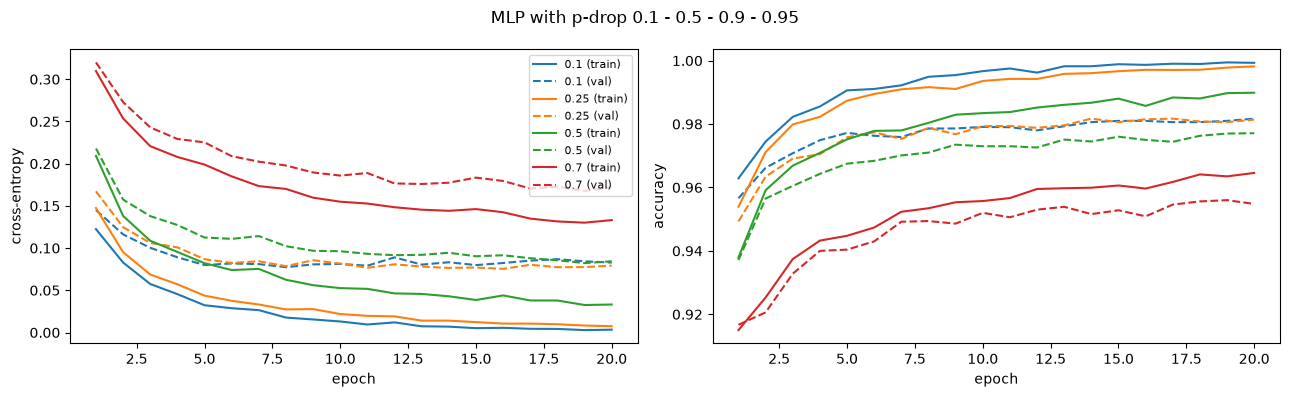

In [25]:
P_DROP = [0.1, 0.25, 0.5, 0.7]
mlp_pdrop_result = {}

for pd in P_DROP:
    mlp_pdrop_model = MLP(p_drop= pd, momentum=0.9, verbose=False)
    mlp_pdrop_model.fit(X_train_scaled, y_train, X_val_scaled, y_val)
    mlp_pdrop_result[pd] = (mlp_pdrop_model.history_)
    
MLP.acc_loss_history_plot(mlp_pdrop_result, "MLP with p-drop 0.1 - 0.5 - 0.9 - 0.95")

**Nhận xét – Dropout Rate**

Trong lần chạy này, `p_drop=0.1` cho Validation Accuracy cao nhất, kế đến là `0.25`; `0.5` thấp hơn và `0.7` thấp rõ rệt. Khi Dropout tăng, Train Loss cao hơn và Accuracy tăng chậm hơn, cho thấy mô hình bị regularize mạnh hơn. Dù `0.1` cho kết quả Accuracy, Loss trên tập Train tốt nhất nhưng trên tập Validation thì kết quả tương đương với `0.25`, điều này thể hiện `0.25` cho khả năng chống overfit tốt hơn. Với dữ liệu và cấu hình hiện tại (`momentum=0.9`), `0.25` là ứng viên phù hợp nhất trong các giá trị đã thử.

**Hidden layer size**

**Cách khảo sát Hidden Sizes**

Thử sáu cấu trúc trong `HD_SIZES`, giữ `activation="relu"` và `init="he"`. Với mỗi cấu trúc, ghi số tham số cùng Train/Validation Accuracy tại Epoch có Validation Accuracy cao nhất. So sánh hiệu suất với độ phức tạp để đánh giá lợi ích của mạng rộng hoặc sâu hơn.

In [26]:
HD_SIZES = [[64], [256], [1024], [256, 128], [512, 256, 128], [256, 256, 256, 256]]
hidden_size_result = []   # (structure, number of parameters, train acc at best-val epoch, best val acc)

for sizes in HD_SIZES:
    mlp_hs_model = MLP(hidden_sizes=sizes, activation="relu", init="he", verbose=False)
    mlp_hs_model.fit(X_train_scaled, y_train, X_val_scaled, y_val)
    name = " -> ".join(map(str, sizes))
    hist = mlp_hs_model.history_
    best_epoch = int(np.argmax(hist["val_acc"]))
    train_acc_at_best = hist["train_acc"][best_epoch]
    best_val_acc = hist["val_acc"][best_epoch]
    hidden_size_result.append((name, MLP.n_params(mlp_hs_model.model_), train_acc_at_best, best_val_acc))

print(f"{'kien truc':>24} | {'tham so':>9} | {'train acc':>9} | {'val acc':>7}")
for name, npar, ta, va in hidden_size_result:
    print(f"{name:>24} | {npar:>9,} | {ta:9.4f} | {va:7.4f}")

               kien truc |   tham so | train acc | val acc
                      64 |    50,890 |    0.9674 |  0.9564
                     256 |   203,530 |    0.9751 |  0.9657
                    1024 |   814,090 |    0.9803 |  0.9696
              256 -> 128 |   235,146 |    0.9912 |  0.9724
       512 -> 256 -> 128 |   567,434 |    0.9979 |  0.9774
256 -> 256 -> 256 -> 256 |   400,906 |    0.9975 |  0.9764


**Nhận xét và đánh giá:**

- Với mạng có 1 hidden layer, khi tăng số neuron từ 64 lên 1024, Validation Accuracy tăng từ 0.9564 lên 0.9696. Tuy nhiên, số lượng tham số cũng tăng đáng kể.
- Các kiến trúc có nhiều hidden layer cho kết quả tốt hơn. Cụ thể, mạng `256 → 128` đạt Val Accuracy 0.9724, cao hơn mạng một lớp 1024 neuron (0.9696) dù có ít tham số hơn.
- Kiến trúc `512 → 256 → 128` đạt kết quả tốt nhất với Val Accuracy 0.9774. Kiến trúc `256 → 256 → 256 → 256` cũng cho kết quả gần tương đương (0.9764), nhưng sử dụng ít tham số hơn.

Kiến trúc `512 → 256 → 128` cho khả năng tổng quát hóa tốt nhất trong các lựa chọn khảo sát. Tuy nhiên, khoảng cách giữa Train Accuracy và Val Accuracy ở các mạng nhiều lớp cho thấy có dấu hiệu overfitting nhẹ và số tham số cũng lớn gấp đôi so với cấu trúc `256 -> 128`. Vì vậy, cần cân nhắc giữa độ chính xác và độ phức tạp của mô hình khi lựa chọn kiến trúc.

**Activision and Vanishing gradient**

**Khảo sát Activation và Vanishing Gradient**

Dùng mạng sâu 6 lớp ẩn để so sánh sigmoid–Xavier, tanh–Xavier và ReLU–He. Đo gradient norm theo lớp lúc khởi tạo, sau đó huấn luyện mô hình riêng và so sánh Learning Curves. Vì mỗi activation đi kèm một initialization, chưa thể quy toàn bộ khác biệt chỉ cho activation.

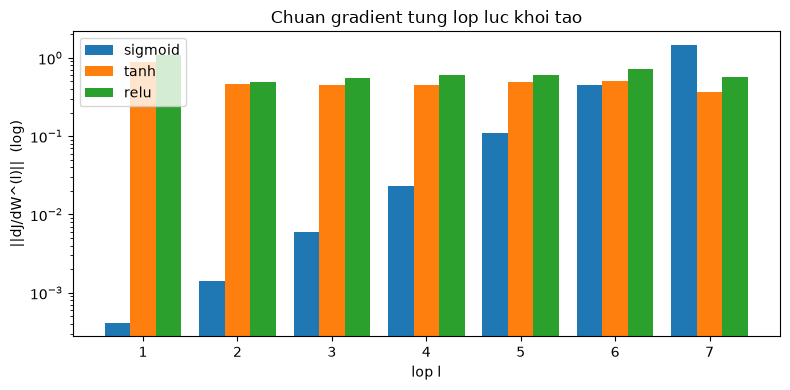

sigmoid: lop 1 = 4.16e-04 | lop cuoi = 1.45e+00 | lop cuoi / lop 1 = 3496.5
   tanh: lop 1 = 8.80e-01 | lop cuoi = 3.70e-01 | lop cuoi / lop 1 = 0.4
   relu: lop 1 = 1.10e+00 | lop cuoi = 5.79e-01 | lop cuoi / lop 1 = 0.5


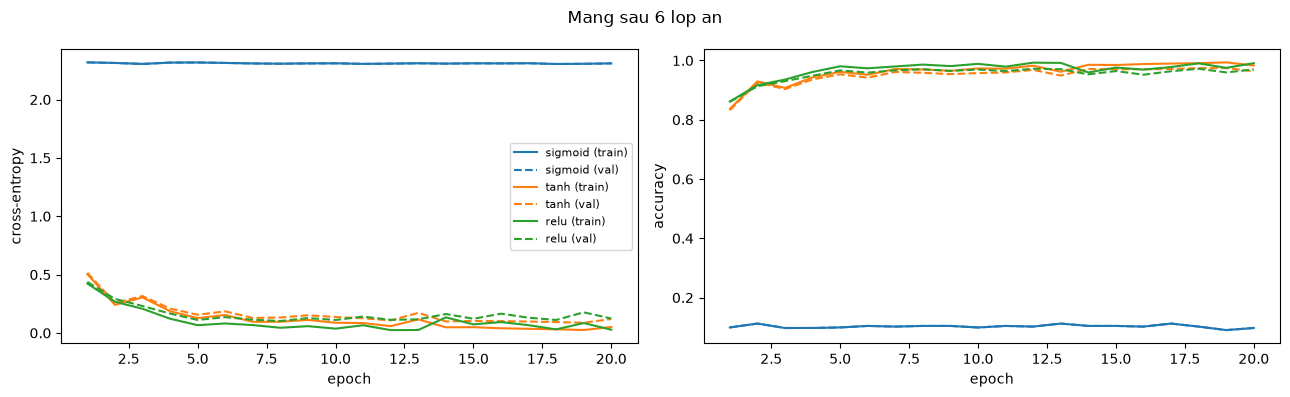

In [27]:
DEEP = [784] + [128] * 6 + [10]
act_setups = {"sigmoid": "xavier", "tanh": "xavier", "relu": "he"}
grad_norms, hist_act = {}, {}

for act, init in act_setups.items():
    # Mang thu gradient va mang huan luyen la hai mang rieng biet.
    mlp_act_model = MLP(hidden_sizes=DEEP[1:-1], activation=act, init=init, verbose=False)
    mlp_act_model.model_ = mlp_act_model.build_mlp(DEEP, activation=act, init=init)
    grad_norms[act] = MLP.layer_grad_norms(mlp_act_model.model_, X_train_scaled[:512], y_train[:512])

    mlp_act_train = MLP(hidden_sizes=DEEP[1:-1], activation=act, init=init, verbose=False)
    mlp_act_train.fit(X_train_scaled, y_train, X_val_scaled, y_val)
    hist_act[act] = mlp_act_train.history_

fig, ax = plt.subplots(figsize=(8, 4))
w = 0.27
for k, act in enumerate(grad_norms):
    ax.bar(np.arange(1, len(DEEP)) + (k - 1) * w, grad_norms[act], width=w, label=act)
ax.set_yscale("log"); ax.set_xlabel("lop l"); ax.set_ylabel("||dJ/dW^(l)||  (log)")
ax.set_title("Chuan gradient tung lop luc khoi tao"); ax.legend()
plt.tight_layout(); plt.show()

for act, gn in grad_norms.items():
    print(f"{act:>7}: lop 1 = {gn[0]:.2e} | lop cuoi = {gn[-1]:.2e} | lop cuoi / lop 1 = {gn[-1] / gn[0]:.1f}")
if hist_act:
    MLP.acc_loss_history_plot(hist_act, "Mang sau 6 lop an")

**Nhận xét – Activation và Vanishing Gradient**

Gradient norm ở lớp đầu của sigmoid rất nhỏ (4.16×10⁻⁴), trong khi ở lớp cuối đạt 1.45 cho thấy sigmoid không phù hợp làm hàm activation trong nhiều lớp liên tục; tỷ lệ lớp cuối/lớp đầu là 3496.5. Với tanh và ReLU, tỷ lệ tương ứng là 0.4 và 0.5, cho thấy gradient không suy giảm theo cùng xu hướng trong phép đo này. Learning Curves bổ sung thông tin về hiệu suất sau huấn luyện. Tuy nhiên, vì initialization khác nhau giữa các activation, kết quả chỉ phản ánh các cặp cấu hình đã thử.

**Initialization**

**Cách khảo sát Initialization**

Phần (a) so sánh `const` và `xavier` trên mạng một lớp ẩn để kiểm tra số neuron có trọng số khác nhau và Validation Accuracy tốt nhất. Phần (b) so sánh Xavier/He qua độ lệch chuẩn đầu ra ReLU ở mạng sâu lúc khởi tạo. Đây là kiểm tra cơ chế khởi tạo, không phải Learning Curves.

  const: so noron an khac nhau =  1 / 64 | val acc = 0.4001
 xavier: so noron an khac nhau = 64 / 64 | val acc = 0.9526
 xavier: std lop 1 = 0.244 | lop 10 = 0.0121 | ti le trung binh moi lop = 0.717
     he: std lop 1 = 0.278 | lop 10 = 0.2696 | ti le trung binh moi lop = 0.997


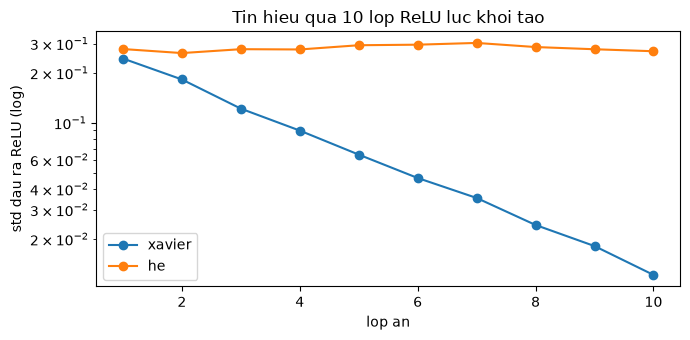

In [28]:
# (a) Doi xung
sym = {}
for init in ["const", "xavier"]:

    mlp_init_model = MLP(hidden_sizes=[64], activation="tanh", init=init, verbose=False)
    mlp_init_model.fit(X_train_scaled, y_train, X_val_scaled, y_val)
    hist = mlp_init_model.history_

    # Dem so hang trong W dau tien khac nhau.
    first_linear = next(layer for layer in mlp_init_model.model_ if isinstance(layer, nn.Linear))
    n_different = torch.unique(first_linear.weight.detach(), dim=0).shape[0]
    val_acc = max(hist["val_acc"]) if hist["val_acc"] else float("nan")
    sym[init] = (n_different, val_acc)

for init, (nd, va) in sym.items():
    print(f"{init:>7}: so noron an khac nhau = {nd:2d} / 64 | val acc = {va:.4f}")


# (b) Do lech chuan tin hieu qua cac lop ReLU

DEEP10 = [784] + [256] * 10 + [10]
fig, ax = plt.subplots(figsize=(7, 3.5))
for init in ["xavier", "he"]:
    deep10_model = MLP(hidden_sizes=DEEP10, init=init)
    deep10_model.model_ = deep10_model.build_mlp(DEEP10, init=init)
    stds = MLP.relu_output_stds(deep10_model.model_, X_train_scaled[:1000])
    ax.plot(range(1, 11), stds, "o-", label=init)
    print(f"{init:>7}: std lop 1 = {stds[0]:.3f} | lop 10 = {stds[-1]:.4f} | ti le trung binh moi lop = {(stds[-1] / stds[0]) ** (1 / 9):.3f}")
ax.set_yscale("log"); ax.set_xlabel("lop an"); ax.set_ylabel("std dau ra ReLU (log)")
ax.set_title("Tin hieu qua 10 lop ReLU luc khoi tao"); ax.legend()
plt.tight_layout(); plt.show()

**Nhận xét – Initialization**

Với khởi tạo `const`, 64 neuron lớp ẩn chỉ có 1 hàng trọng số khác nhau và Validation Accuracy tốt nhất là 0.3900. Với `xavier`, cả 64 neuron có trọng số khác nhau và Accuracy đạt 0.9526; kết quả minh họa vấn đề đối xứng khi khởi tạo cùng hằng số. Ở mạng sâu ReLU, độ lệch chuẩn với Xavier giảm từ 0.244 xuống 0.0121, trong khi He duy trì gần như ổn định từ 0.278 xuống 0.2696. Vì vậy He phù hợp hơn trong phép thử mạng ReLU sâu này.

**Kết quả sau khảo sát với Early Stopping**

In [29]:
from src.algorithm.MLP import MLP

mlp_model = MLP(learning_rate=0.1, momentum=0.9, batch_size=256, weight_decay=0.0002,
                hidden_sizes=[256, 128], activation="relu", init="he", p_drop= 0.21,
                n_epochs= 50, early_stop= True, patience= 10, verbose= True)

mlp_model.fit(X_train_scaled, y_train, X_val_scaled, y_val)

mlp_y_pred = mlp_model.predict(X_test_scaled)

y_test = np.asarray(y_test)
accuracy = np.mean(mlp_y_pred == y_test)
accuracy_mlp = accuracy
time_mlp = mlp_model.count_training_time

print("Test accuracy:", accuracy)

epoch  1 |   0.3s | train loss 0.1389 acc 0.9558 | val loss 0.1567 acc 0.9510
epoch  2 |   0.3s | train loss 0.0976 acc 0.9702 | val loss 0.1289 acc 0.9605
epoch  3 |   0.3s | train loss 0.0756 acc 0.9770 | val loss 0.1141 acc 0.9653
epoch  4 |   0.3s | train loss 0.0564 acc 0.9827 | val loss 0.0952 acc 0.9725
epoch  5 |   0.3s | train loss 0.0481 acc 0.9853 | val loss 0.0909 acc 0.9735
epoch  6 |   0.3s | train loss 0.0410 acc 0.9876 | val loss 0.0819 acc 0.9764
epoch  7 |   0.3s | train loss 0.0404 acc 0.9883 | val loss 0.0857 acc 0.9764
epoch  8 |   0.3s | train loss 0.0336 acc 0.9898 | val loss 0.0825 acc 0.9759
epoch  9 |   0.3s | train loss 0.0260 acc 0.9921 | val loss 0.0772 acc 0.9786
epoch 10 |   0.3s | train loss 0.0236 acc 0.9934 | val loss 0.0784 acc 0.9788
epoch 11 |   0.3s | train loss 0.0204 acc 0.9945 | val loss 0.0731 acc 0.9794
epoch 12 |   0.3s | train loss 0.0261 acc 0.9924 | val loss 0.0796 acc 0.9784
epoch 13 |   0.4s | train loss 0.0197 acc 0.9946 | val loss 0.07

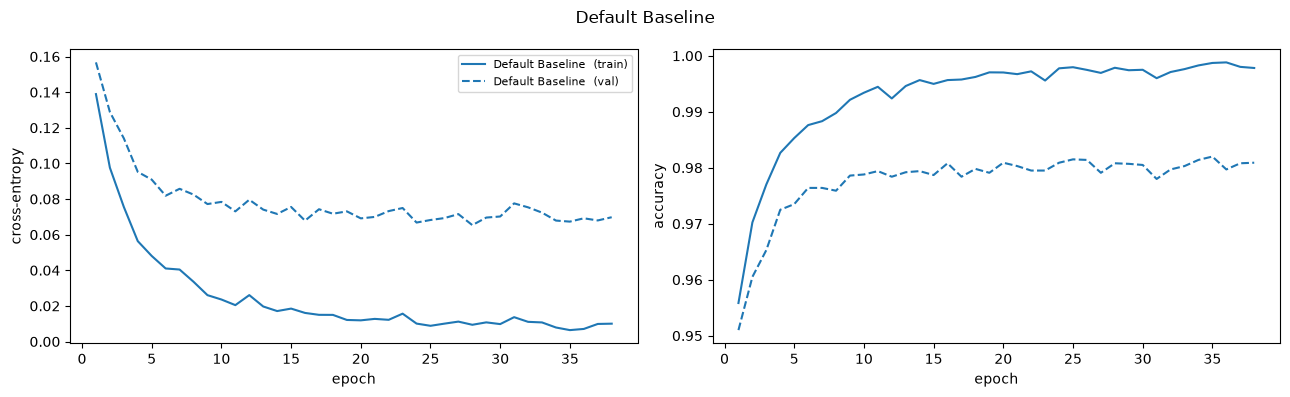

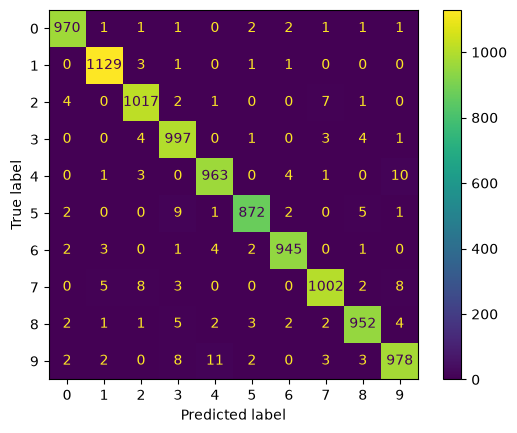

In [30]:

MLP.acc_loss_history_plot({"Default Baseline ": mlp_model.history_}, "Default Baseline")

mlp_cm = confusion_matrix(y_test, mlp_y_pred)

ConfusionMatrixDisplay(confusion_matrix=mlp_cm).plot()
plt.show()

# 2.5 Ensemble
## 2.5.1 Bagging
### 2.5.1.1 KNN

In [31]:
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
import time

knn = KNeighborsClassifier(n_neighbors=3, weights='distance', n_jobs=-1)

print("Đang huấn luyện mô hình KNN...")
start_time = time.time()
knn.fit(X_train_scaled, y_train)
end_time = time.time()
knn_training_time = end_time - start_time
knn_y_pred = knn.predict(X_test_scaled)

accuracy_knn = accuracy_score(y_test, knn_y_pred)
print(f"\nĐộ chính xác (Accuracy): {accuracy_knn * 100:.2f}%")

print(f"excution time KNN: {knn_training_time:.4f} giây")
print("\nBáo cáo phân loại chi tiết từng chữ số:")
print(classification_report(y_test, knn_y_pred))

Đang huấn luyện mô hình KNN...

Độ chính xác (Accuracy): 97.00%
excution time KNN: 0.0960 giây

Báo cáo phân loại chi tiết từng chữ số:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.96      1.00      0.98      1135
           2       0.99      0.96      0.98      1032
           3       0.97      0.97      0.97      1010
           4       0.98      0.96      0.97       982
           5       0.96      0.96      0.96       892
           6       0.98      0.98      0.98       958
           7       0.96      0.96      0.96      1028
           8       0.98      0.95      0.96       974
           9       0.95      0.96      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



### 2.5.1.2 RandomForest

In [32]:

import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# Initialize Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    criterion="gini",
    random_state=42,
    n_jobs=4
)

# Train the model and measure training time
start_time = time.perf_counter()

rf_model.fit(X_train_scaled, y_train)

time_rf = time.perf_counter() - start_time

# Make predictions
rf_y_pred = rf_model.predict(X_test_scaled)

# Evaluate the model
print("Classification Report for Random Forest:")

print(
    classification_report(
        y_test,
        rf_y_pred,
        target_names=rf_model.classes_.astype(str),
        zero_division=0
    )
)
accuracy_rf = rf_model.score(X_test_scaled, y_test)
print(f"Accuracy of Random Forest on test set: {accuracy_rf:.2%}")
print(f"Training time: {time_rf:.4f} seconds")



Classification Report for Random Forest:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.96      0.97      0.96      1032
           3       0.96      0.96      0.96      1010
           4       0.97      0.97      0.97       982
           5       0.97      0.96      0.97       892
           6       0.97      0.98      0.97       958
           7       0.97      0.96      0.96      1028
           8       0.96      0.95      0.96       974
           9       0.95      0.95      0.95      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000

Accuracy of Random Forest on test set: 96.68%
Training time: 4.7938 seconds


### 2.5.1.3 Create a table comparing the accuracy and execution time of the algorithms.

In [33]:
import pandas as pd
import numpy as np

# Number of test samples
n_test = len(y_test)

# Collect model evaluation results
results = [
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_lr,
        "Execution Time (s)": time_lr,
        "Notes": "Linear model"
    },
    {
        "Model": "KNN (k=3)",
        "Accuracy": accuracy_knn,
        "Execution Time (s)": knn_training_time,
        "Notes": "Distance-based learning"
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_rf,
        "Execution Time (s)": time_rf,
        "Notes": "Bagging ensemble"
    },
    {
        "Model": "Naive Bayes",
        "Accuracy": accuracy_nb,
        "Execution Time (s)": time_nb,
        "Notes": "Probabilistic model"
    },
    {
        "Model": "MLP",
        "Accuracy": accuracy_mlp,
        "Execution Time (s)": time_mlp,
        "Notes": "Neural network"
    }
]

# Create DataFrame
df_results = pd.DataFrame(results)

# Calculate the number of incorrect predictions
df_results["Incorrect Predictions"] = (
    (1 - df_results["Accuracy"]) * n_test
).round().astype(int)

# Convert accuracy into percentage
df_results["Accuracy"] = (
    df_results["Accuracy"] * 100
).round(2)

# Reorder columns
df_results = df_results[
    [
        "Model",
        "Accuracy",
        "Incorrect Predictions",
        "Execution Time (s)",
        "Notes"
    ]
]

# Sort models by accuracy (descending)
df_results = df_results.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

# Display results
display(df_results.style.format({
    "Accuracy": "{:.2f}%",
    "Execution Time (s)": "{:.2f}s"
}).highlight_max(
    subset=["Accuracy"],
    color="#6A470C"
))


,Model,Accuracy,Incorrect Predictions,Execution Time (s),Notes
0,MLP,98.25%,175,13.74s,Neural network
1,KNN (k=3),97.00%,300,0.10s,Distance-based learning
2,Random Forest,96.68%,332,4.79s,Bagging ensemble
3,Logistic Regression,92.04%,796,4.78s,Linear model
4,Naive Bayes,83.51%,1649,0.24s,Probabilistic model


### 2.5.1.4 Create a table comparing image discrepancies across models

In [34]:
import pandas as pd
import numpy as np

# 1. Gom dữ liệu thực tế (y_test) và các dự đoán vào DataFrame
# Giả sử bạn đã có y_test và y_pred của các mô hình
df = pd.DataFrame({
    'Thuc_te': y_test,
    'LogisticRegression': y_pred_lr,
    'RandomForest': rf_y_pred,
    'KNN': knn_y_pred,
    'MLP': mlp_y_pred
})

# 2. Khởi tạo danh sách lưu kết quả
error_analysis = []

models = ['LogisticRegression', 'RandomForest', 'KNN'] # Danh sách các mô hình muốn so sánh với MLP

for model in models:
    # Trường hợp 1: Mô hình sai NHƯNG MLP đúng 
    # (MLP đã học được cách sửa lỗi của mô hình này)
    model_wrong_mlp_right = ((df[model] != df['Thuc_te']) & (df['MLP'] == df['Thuc_te'])).sum()
    
    # Trường hợp 2: MLP sai NHƯNG Mô hình đúng 
    # (MLP bỏ qua/đánh mất thông tin đúng của mô hình này)
    mlp_wrong_model_right = ((df['MLP'] != df['Thuc_te']) & (df[model] == df['Thuc_te'])).sum()
    
    # Trường hợp 3: Cả hai CÙNG SAI, NHƯNG ra hai đáp án khác nhau 
    # (Ví dụ: Số 7, mô hình đoán là 1, MLP đoán là 9)
    both_wrong_diff = ((df[model] != df['Thuc_te']) & 
                       (df['MLP'] != df['Thuc_te']) & 
                       (df[model] != df['MLP'])).sum()
                       
    # (Tùy chọn) Trường hợp 4: Cả hai cùng sai và ra cùng 1 đáp án sai
    both_wrong_same = ((df[model] != df['Thuc_te']) & 
                       (df['MLP'] != df['Thuc_te']) & 
                       (df[model] == df['MLP'])).sum()

    error_analysis.append({
        'Mô hình so sánh': model,
        'Mô hình Sai, MLP Đúng': model_wrong_mlp_right,
        'MLP Sai, Mô hình Đúng': mlp_wrong_model_right,
        'Cùng Sai (Khác đáp án)': both_wrong_diff,
        'Cùng Sai (Giống đáp án)': both_wrong_same
    })

# 3. Hiển thị bảng
df_errors = pd.DataFrame(error_analysis)
print("BẢNG PHÂN TÍCH ẢNH DỰ ĐOÁN SAI SO VỚI MLP:\n")
print(df_errors.to_string(index=False))

BẢNG PHÂN TÍCH ẢNH DỰ ĐOÁN SAI SO VỚI MLP:

   Mô hình so sánh  Mô hình Sai, MLP Đúng  MLP Sai, Mô hình Đúng  Cùng Sai (Khác đáp án)  Cùng Sai (Giống đáp án)
LogisticRegression                   8855                     11                     142                       22
      RandomForest                    204                     47                      25                      103
               KNN                    198                     73                      21                       81


In [35]:
from src.algorithm.NaiveBayes import NaiveBayes, gaussian_log_pdf
from src.algorithm.Logistic_Regression import LogisticRegression
from src.algorithm.Ensemble import ManualStackingEnsemble
from src.algorithm.MLP import MLP



model_nb = NaiveBayes(log_pdf=gaussian_log_pdf)
model_lr = LogisticRegression()
model_mlp = MLP()
model_knn = KNeighborsClassifier(n_neighbors=3, weights='distance', n_jobs=-1)
model_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    criterion="gini",
    random_state=42,
    n_jobs=4
)
ensemble = ManualStackingEnsemble(
    base_models=[model_knn, model_mlp, model_rf],
    meta_model=LogisticRegression(),
    cv_folds=5
)

# training the ensemble model and evaluating its performance on the test set
ensemble.fit(X_train_scaled, y_train, X_test_scaled, y_test)
accuracy = ensemble.evaluate(X_test_scaled, y_test)
print(f"Stacking Ensemble Accuracy trên MNIST: {accuracy * 100:.2f}%")
print(f"thời gian chạy Stacking Ensemble: {ensemble.count_training_time:.4f} giây")


Stacking Ensemble Accuracy trên MNIST: 97.77%
thời gian chạy Stacking Ensemble: 632.8634 giây


## 2.5.2 Adaboost

In [36]:
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report


# 2. Khởi tạo mô hình cơ sở và AdaBoost
# Dùng cây max_depth=3 giúp nhận diện các đường nét đặc trưng của chữ số tốt hơn cây độ sâu 1 (stump)
base_estimator = DecisionTreeClassifier(max_depth=3, random_state=42)

model_ada = AdaBoostClassifier(
    estimator=base_estimator,
    n_estimators=50,       # Số lượng cây kết hợp
    learning_rate=1,     # Tốc độ học (độ đóng góp của từng cây)
    random_state=42
)

# 3. Huấn luyện mô hình
print("Đang huấn luyện AdaBoost...")
model_ada.fit(X_train_scaled, y_train)

# 4. Dự đoán và đánh giá
y_pred = model_ada.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)

print(f"\nĐộ chính xác (Accuracy): {acc * 100:.2f}%\n")
print("Báo cáo phân loại chi tiết từng chữ số:")
print(classification_report(y_test, y_pred))

Đang huấn luyện AdaBoost...

Độ chính xác (Accuracy): 85.82%

Báo cáo phân loại chi tiết từng chữ số:
              precision    recall  f1-score   support

           0       0.95      0.93      0.94       980
           1       0.93      0.95      0.94      1135
           2       0.85      0.85      0.85      1032
           3       0.83      0.80      0.82      1010
           4       0.79      0.85      0.82       982
           5       0.79      0.83      0.81       892
           6       0.92      0.90      0.91       958
           7       0.92      0.83      0.87      1028
           8       0.82      0.88      0.85       974
           9       0.79      0.76      0.77      1009

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



# 2.6.CNN

In [37]:
cnn_model_1 = CNN(n_filters = 32, n_filters2 = 64)
cnn_model_1.fit(X_train_scaled, y_train, X_val_scaled, y_val)

Epoch 001/030 | Train objective (online): 0.194923 | LR: 0.001 | Val loss: 0.069854 | Val accuracy: 98.2000% | 58.5s
Epoch 002/030 | Train objective (online): 0.085619 | LR: 0.001 | Val loss: 0.046076 | Val accuracy: 98.5800% | 53.2s
Epoch 003/030 | Train objective (online): 0.067879 | LR: 0.001 | Val loss: 0.048460 | Val accuracy: 98.6100% | 53.2s
Epoch 004/030 | Train objective (online): 0.062615 | LR: 0.001 | Val loss: 0.037116 | Val accuracy: 98.8400% | 56.0s
Epoch 005/030 | Train objective (online): 0.059109 | LR: 0.001 | Val loss: 0.045909 | Val accuracy: 98.5900% | 53.4s
Epoch 006/030 | Train objective (online): 0.055254 | LR: 0.001 | Val loss: 0.041216 | Val accuracy: 98.7000% | 54.1s
Epoch 007/030 | Train objective (online): 0.044002 | LR: 0.0005 | Val loss: 0.032116 | Val accuracy: 98.9600% | 53.3s
Epoch 008/030 | Train objective (online): 0.041490 | LR: 0.0005 | Val loss: 0.034135 | Val accuracy: 98.9400% | 54.1s
Epoch 009/030 | Train objective (online): 0.040632 | LR: 0.000

## 2.6.1 Confusion Matrix

Validation accuracy: 99.2400%
Correct predictions: 9924 / 10000
Incorrect predictions: 76


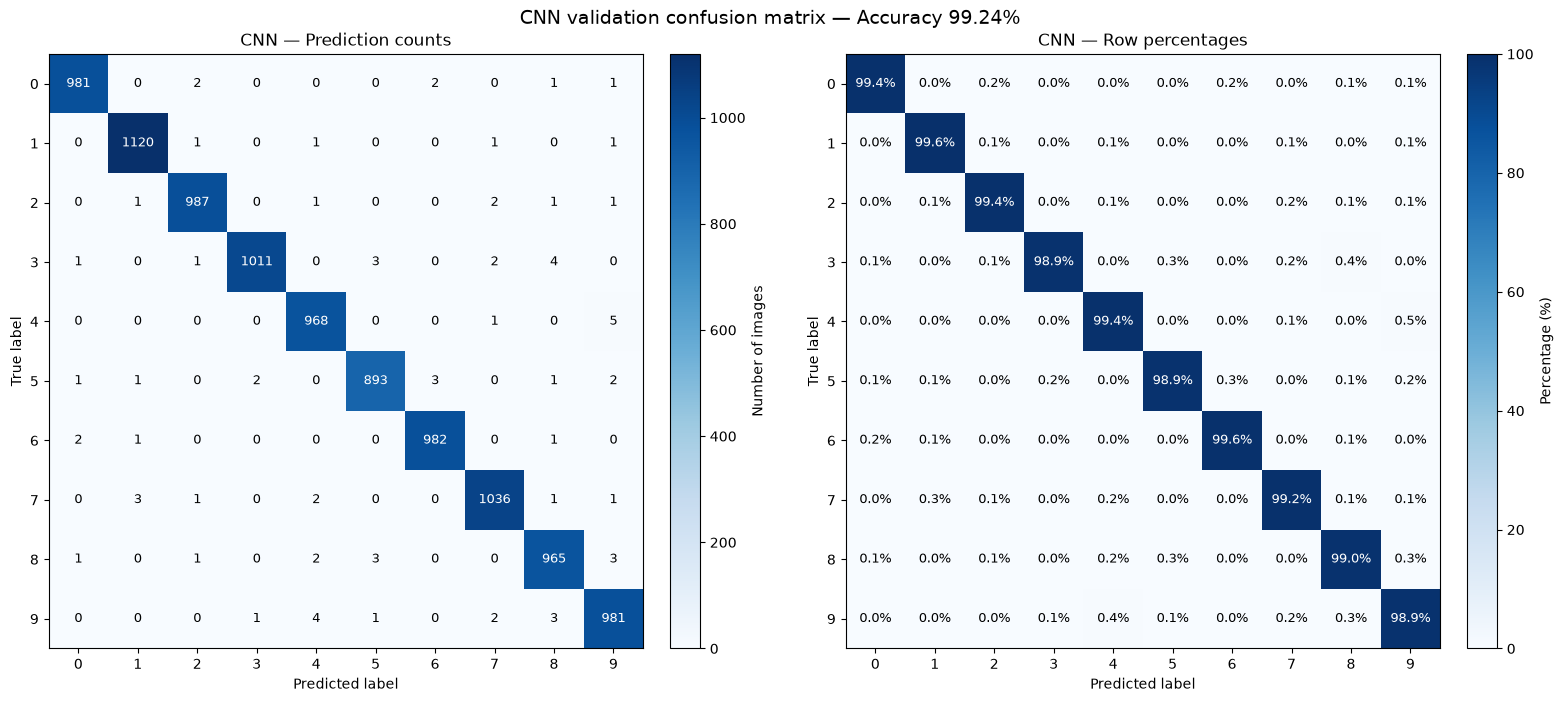

In [38]:
y_pred = cnn_model_1.predict(X_val_scaled)
y_true = np.asarray(y_val)
n_classes = cnn_model_1.n_classes

if (
    y_true.shape != y_pred.shape
    or y_true.dtype.kind not in "iu"
    or np.any(y_true < 0)
    or np.any(y_true >= n_classes)
):
    raise ValueError("y_val must contain one valid integer label per image.")

# Rows represent true labels; columns represent predicted labels.
cm = np.zeros((n_classes, n_classes), dtype=np.int64)
np.add.at(cm, (y_true, y_pred), 1)

# Normalize by the number of samples in each true class.
row_totals = cm.sum(axis=1, keepdims=True)
cm_percent = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=np.float64),
    where=row_totals != 0,
) * 100

accuracy = np.mean(y_true == y_pred)
print(f"Validation accuracy: {accuracy:.4%}")
print(f"Correct predictions: {np.trace(cm)} / {cm.sum()}")
print(f"Incorrect predictions: {cm.sum() - np.trace(cm)}")

# Plot counts and row-normalized percentages.
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, matrix, normalized in zip(
    axes, [cm, cm_percent], [False, True]
):
    image = ax.imshow(
        matrix,
        cmap="Blues",
        vmin=0,
        vmax=100 if normalized else max(1, int(cm.max())),
    )

    threshold = image.norm.vmax / 2

    for row in range(n_classes):
        for column in range(n_classes):
            value = matrix[row, column]
            label = f"{value:.1f}%" if normalized else str(int(value))

            ax.text(
                column, row, label,
                ha="center",
                va="center",
                fontsize=9,
                color="white" if value > threshold else "black",
            )

    ax.set_xticks(np.arange(n_classes))
    ax.set_yticks(np.arange(n_classes))
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(
        "CNN — Row percentages"
        if normalized else "CNN — Prediction counts"
    )

    fig.colorbar(
        image,
        ax=ax,
        fraction=0.046,
        pad=0.04,
        label="Percentage (%)" if normalized else "Number of images",
    )

fig.suptitle(
    f"CNN validation confusion matrix — Accuracy {accuracy:.2%}",
    fontsize=14,
)
fig.tight_layout()
plt.show()

# Data augement

In [39]:
from data.preprocessing_mnist_400k import (
    X_train_scaled,
    X_val_scaled,
    X_test_scaled,
    y_train,
    y_val,
    y_test,
)
X_train_scaled_au_cnn = X_train_scaled
X_val_scaled_au_cnn = X_val_scaled
X_test_scaled_au_cnn = X_test_scaled
y_train_cnn = y_train
y_val_cnn = y_val
y_test_cnn = y_test
print(X_train_scaled_au_cnn.shape)

(299989, 784)


# CNN with data agument

In [40]:
cnn_model = CNN(n_filters = 32, n_filters2 = 64, n_epochs = 25)
cnn_model.fit(X_train_scaled_au_cnn, y_train_cnn, X_val_scaled_au_cnn, y_val_cnn)

Epoch 001/025 | Train objective (online): 0.237875 | LR: 0.001 | Val loss: 0.105706 | Val accuracy: 96.7939% | 322.9s
Epoch 002/025 | Train objective (online): 0.132811 | LR: 0.001 | Val loss: 0.069933 | Val accuracy: 97.8687% | 327.1s
Epoch 003/025 | Train objective (online): 0.117211 | LR: 0.001 | Val loss: 0.069906 | Val accuracy: 97.8371% | 338.6s
Epoch 004/025 | Train objective (online): 0.109051 | LR: 0.001 | Val loss: 0.067776 | Val accuracy: 97.9437% | 358.4s
Epoch 005/025 | Train objective (online): 0.102968 | LR: 0.001 | Val loss: 0.066388 | Val accuracy: 97.9354% | 333.5s
Epoch 006/025 | Train objective (online): 0.099987 | LR: 0.001 | Val loss: 0.060408 | Val accuracy: 98.1270% | 327.7s
Epoch 007/025 | Train objective (online): 0.096052 | LR: 0.001 | Val loss: 0.064626 | Val accuracy: 98.0820% | 320.7s
Epoch 008/025 | Train objective (online): 0.094469 | LR: 0.001 | Val loss: 0.055525 | Val accuracy: 98.2637% | 331.1s
Epoch 009/025 | Train objective (online): 0.091347 | LR:

# Confusion matrix

Validation accuracy: 98.9250%
Correct predictions: 39570 / 40000
Incorrect predictions: 430


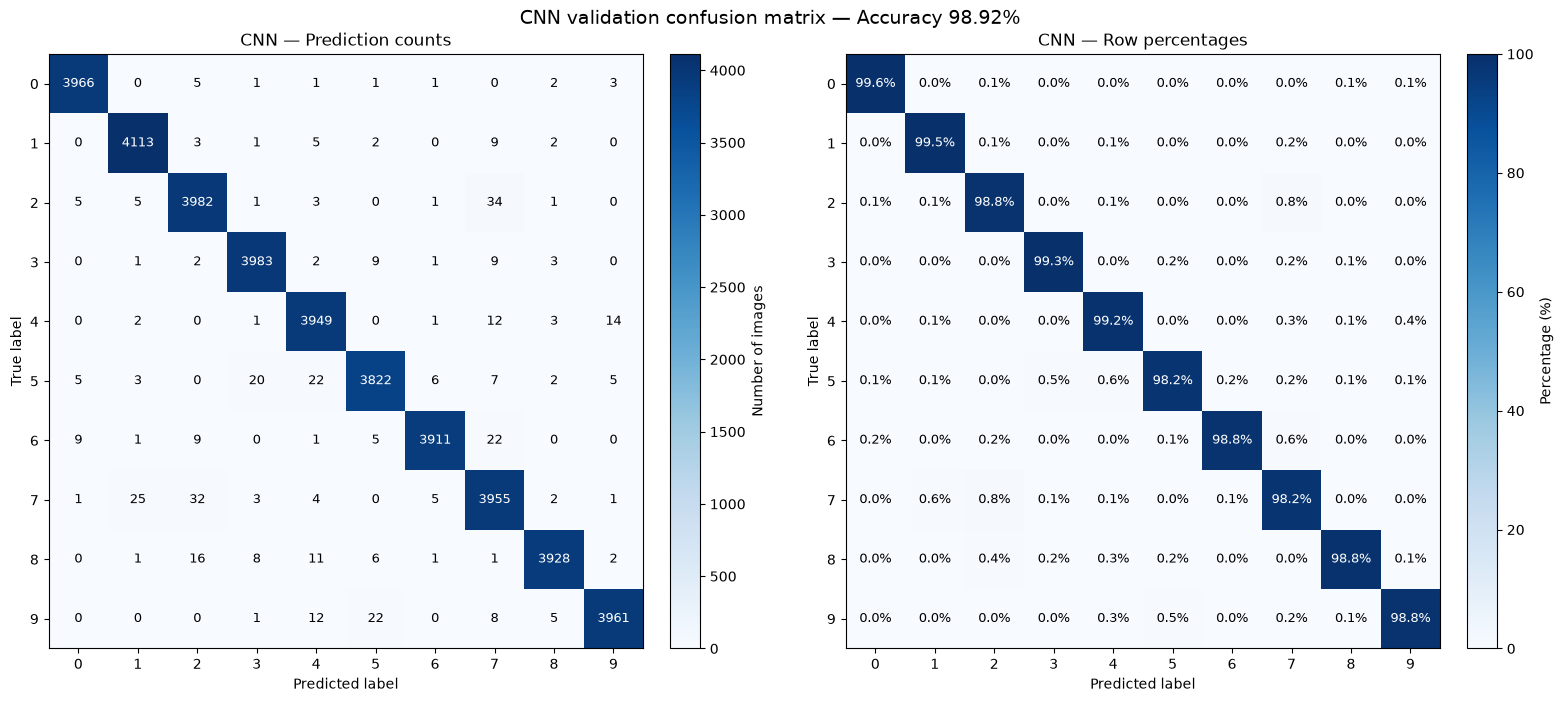

In [41]:
y_pred = cnn_model.predict(X_test_scaled_au_cnn)
y_true = np.asarray(y_test_cnn)
n_classes = cnn_model.n_classes

if (
    y_true.shape != y_pred.shape
    or y_true.dtype.kind not in "iu"
    or np.any(y_true < 0)
    or np.any(y_true >= n_classes)
):
    raise ValueError("y_val must contain one valid integer label per image.")

# Rows represent true labels; columns represent predicted labels.
cm = np.zeros((n_classes, n_classes), dtype=np.int64)
np.add.at(cm, (y_true, y_pred), 1)

# Normalize by the number of samples in each true class.
row_totals = cm.sum(axis=1, keepdims=True)
cm_percent = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=np.float64),
    where=row_totals != 0,
) * 100

accuracy = np.mean(y_true == y_pred)
print(f"Validation accuracy: {accuracy:.4%}")
print(f"Correct predictions: {np.trace(cm)} / {cm.sum()}")
print(f"Incorrect predictions: {cm.sum() - np.trace(cm)}")

# Plot counts and row-normalized percentages.
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, matrix, normalized in zip(
    axes, [cm, cm_percent], [False, True]
):
    image = ax.imshow(
        matrix,
        cmap="Blues",
        vmin=0,
        vmax=100 if normalized else max(1, int(cm.max())),
    )

    threshold = image.norm.vmax / 2

    for row in range(n_classes):
        for column in range(n_classes):
            value = matrix[row, column]
            label = f"{value:.1f}%" if normalized else str(int(value))

            ax.text(
                column, row, label,
                ha="center",
                va="center",
                fontsize=9,
                color="white" if value > threshold else "black",
            )

    ax.set_xticks(np.arange(n_classes))
    ax.set_yticks(np.arange(n_classes))
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(
        "CNN — Row percentages"
        if normalized else "CNN — Prediction counts"
    )

    fig.colorbar(
        image,
        ax=ax,
        fraction=0.046,
        pad=0.04,
        label="Percentage (%)" if normalized else "Number of images",
    )

fig.suptitle(
    f"CNN validation confusion matrix — Accuracy {accuracy:.2%}",
    fontsize=14,
)
fig.tight_layout()
plt.show()

# Save weights of models

In [42]:
from pathlib import Path
from typing import Any
import joblib


def save_model(model: Any, filename: str) -> Path:
    """Save a trained model to disk.

    Parameters
    ----------
    model : Any
        A fitted machine learning model.
    filename : str
        Name of the saved model file.

    Returns
    -------
    Path
        Path to the saved model.
    """
    path = model_dir / filename

    joblib.dump(model, path, compress=3)

    print(f"Model saved successfully: {path}")
    return path


def load_model(filename: str) -> Any:
    """Load a previously trained model from disk.

    Parameters
    ----------
    filename : str
        Name of the saved model file.

    Returns
    -------
    Any
        The restored model.
    """
    path = model_dir / filename

    if not path.is_file():
        raise FileNotFoundError(
            f"Model file does not exist: {path}"
        )

    model = joblib.load(path)

    print(f"Model loaded successfully: {path}")
    return model

In [43]:
save_model(cnn_model, "cnn.joblib")
save_model(nb_model, "naive_bayes.joblib")
save_model(best_model, "logistic_regression.joblib")
save_model(best_svm, "svm.joblib")
save_model(mlp_model, "mlp.joblib")
save_model(ensemble, "ensemble.joblib")
save_model(model_ada, "ada.joblib")
save_model(cnn_model_1, "cnn_no_data_au.joblib")
print("All models saved successfully!")

Model saved successfully: /Users/duongdangkhoa/Work/HCMUS/ky5/pr/handwritten_text_recognition/saved_models/cnn.joblib
Model saved successfully: /Users/duongdangkhoa/Work/HCMUS/ky5/pr/handwritten_text_recognition/saved_models/naive_bayes.joblib
Model saved successfully: /Users/duongdangkhoa/Work/HCMUS/ky5/pr/handwritten_text_recognition/saved_models/logistic_regression.joblib
Model saved successfully: /Users/duongdangkhoa/Work/HCMUS/ky5/pr/handwritten_text_recognition/saved_models/svm.joblib
Model saved successfully: /Users/duongdangkhoa/Work/HCMUS/ky5/pr/handwritten_text_recognition/saved_models/mlp.joblib
Model saved successfully: /Users/duongdangkhoa/Work/HCMUS/ky5/pr/handwritten_text_recognition/saved_models/ensemble.joblib
Model saved successfully: /Users/duongdangkhoa/Work/HCMUS/ky5/pr/handwritten_text_recognition/saved_models/ada.joblib
Model saved successfully: /Users/duongdangkhoa/Work/HCMUS/ky5/pr/handwritten_text_recognition/saved_models/cnn_no_data_au.joblib
All models saved